# Import Libraries

In [ ]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

Repeatition Seed for both Torch and Numpy

In [ ]:
torch.manual_seed(0)
np.random.seed(0)

**Check availabilty of GPU**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


Quaternion to rotation Matrix
**p' = qpq***

q* is a conjugate or inverse of rotation axis q

Now this will result in a 3x1 matrix of the form RP now convert it to p' = RP
use the notation in R to calculate the matrix elements

Rodrigues' rotation formula rotates a vector $\mathbf{p}$ around a unit axis $\mathbf{u}$ by an angle $\theta$:

$$\mathbf{p}' = \mathbf{p} \cos\theta + (\mathbf{u} \times \mathbf{p}) \sin\theta + \mathbf{u}(\mathbf{u} \cdot \mathbf{p})(1 - \cos\theta)$$

The quaternion vector formula connects directly to this through half-angle trigonometric identities and the definition of a unit quaternion.

---

### 1. Parameter Substitution

Recall that a unit quaternion $q = (w, \mathbf{v})$ representing rotation by $\theta$ around unit axis $\mathbf{u}$ is defined as:

$$w = \cos\frac{\theta}{2}, \quad \mathbf{v} = \sin\frac{\theta}{2}\mathbf{u}$$

Substituting $w$ and $\mathbf{v}$ into the quaternion vector formula:

$$\mathbf{p}' = \mathbf{p} + 2w(\mathbf{v} \times \mathbf{p}) + 2\mathbf{v} \times (\mathbf{v} \times \mathbf{p})$$

yields:

$$\mathbf{p}' = \mathbf{p} + 2 \left(\cos\frac{\theta}{2}\right) \left(\sin\frac{\theta}{2}\mathbf{u} \times \mathbf{p}\right) + 2 \left(\sin\frac{\theta}{2}\mathbf{u}\right) \times \left(\sin\frac{\theta}{2}\mathbf{u} \times \mathbf{p}\right)$$

---

### 2. Simplifying via Trigonometric Identities

Factoring out the scalar components:

$$\mathbf{p}' = \mathbf{p} + \left(2\sin\frac{\theta}{2}\cos\frac{\theta}{2}\right)(\mathbf{u} \times \mathbf{p}) + \left(2\sin^2\frac{\theta}{2}\right) \mathbf{u} \times (\mathbf{u} \times \mathbf{p})$$

Applying standard double-angle trigonometric identities:

* **Sine double-angle:** $2\sin\frac{\theta}{2}\cos\frac{\theta}{2} = \sin\theta$
* **Half-angle for sine squared:** $2\sin^2\frac{\theta}{2} = 1 - \cos\theta$

Substituting these gives the **double cross product form of Rodrigues' formula**:

$$\mathbf{p}' = \mathbf{p} + \sin\theta(\mathbf{u} \times \mathbf{p}) + (1 - \cos\theta) \mathbf{u} \times (\mathbf{u} \times \mathbf{p})$$

---

### 3. Converting to the Dot-Product Form

Using the vector triple product identity $\mathbf{u} \times (\mathbf{u} \times \mathbf{p}) = (\mathbf{u} \cdot \mathbf{p})\mathbf{u} - (\mathbf{u} \cdot \mathbf{u})\mathbf{p}$, and since $\Vert{}\mathbf{u}\Vert{} = 1$:

$$\mathbf{u} \times (\mathbf{u} \times \mathbf{p}) = (\mathbf{u} \cdot \mathbf{p})\mathbf{u} - \mathbf{p}$$

Substituting this into the equation:

$$\mathbf{p}' = \mathbf{p} + \sin\theta(\mathbf{u} \times \mathbf{p}) + (1 - \cos\theta)\Big((\mathbf{u} \cdot \mathbf{p})\mathbf{u} - \mathbf{p}\Big)$$

Expanding and collecting the $\mathbf{p}$ terms:

$$\mathbf{p}' = \mathbf{p} - (1 - \cos\theta)\mathbf{p} + \sin\theta(\mathbf{u} \times \mathbf{p}) + (1 - \cos\theta)(\mathbf{u} \cdot \mathbf{p})\mathbf{u}$$

$$\mathbf{p}' = \mathbf{p}\cos\theta + (\mathbf{u} \times \mathbf{p})\sin\theta + \mathbf{u}(\mathbf{u} \cdot \mathbf{p})(1 - \cos\theta)$$

This completes the direct mathematical equivalence.

The output vector $\mathbf{p}'$ and input vector $\mathbf{p}$ are both $3 \times 1$ column vectors. We convert the vector equation into a $3 \times 3$ matrix $R$ by **factoring out** $\mathbf{p} = (p_x, p_y, p_z)^T$ using linear algebra principles.

---

### Method 1: Factoring Coefficients Line by Line

Write out each component of the $3 \times 1$ result $\mathbf{p}' = \mathbf{p} + 2w(\mathbf{v} \times \mathbf{p}) + 2\mathbf{v} \times (\mathbf{v} \times \mathbf{p})$ individually:

$$\begin{bmatrix} p'_x \\ p'_y \\ p'_z \end{bmatrix} = \begin{bmatrix} p_x \\ p_y \\ p_z \end{bmatrix} + 2w \begin{bmatrix} y p_z - z p_y \\ z p_x - x p_z \\ x p_y - y p_x \end{bmatrix} + 2 \begin{bmatrix} -(y^2 + z^2)p_x + x y p_y + x z p_z \\ x y p_x - (x^2 + z^2)p_y + y z p_z \\ x z p_x + y z p_y - (x^2 + y^2)p_z \end{bmatrix}$$

Now, collect and group the terms for $p_x$, $p_y$, and $p_z$ in each row:

* **Row 0 ($p'_x$):**

$$p'_x = (1 - 2y^2 - 2z^2) \cdot p_x + (2xy - 2wz) \cdot p_y + (2xz + 2wy) \cdot p_z$$


* **Row 1 ($p'_y$):**

$$p'_y = (2xy + 2wz) \cdot p_x + (1 - 2x^2 - 2z^2) \cdot p_y + (2yz - 2wx) \cdot p_z$$


* **Row 2 ($p'_z$):**

$$p'_z = (2xz - 2wy) \cdot p_x + (2yz + 2wx) \cdot p_y + (1 - 2x^2 - 2y^2) \cdot p_z$$



By matrix-vector multiplication rules, a linear system of the form:

$$\begin{bmatrix} p'_x \\ p'_y \\ p'_z \end{bmatrix} = \begin{bmatrix} A_x & B_x & C_x \\ A_y & B_y & C_y \\ A_z & B_z & C_z \end{bmatrix} \begin{bmatrix} p_x \\ p_y \\ p_z \end{bmatrix}$$

allows us to read off the coefficients directly to construct the $3 \times 3$ matrix $R$.

---

### Method 2: Using Skew-Symmetric Cross-Product Matrices

Cross products can be written directly as matrix multiplication using a $3 \times 3$ skew-symmetric matrix $[\mathbf{v}]_\times$:

$$\mathbf{v} \times \mathbf{p} = [\mathbf{v}]_\times \mathbf{p} = \begin{bmatrix} 0 & -z & y \\ z & 0 & -x \\ -y & x & 0 \end{bmatrix} \begin{bmatrix} p_x \\ p_y \\ p_z \end{bmatrix}$$

Substituting this matrix representation into the vector equation:

$$\mathbf{p}' = \mathbf{p} + 2w(\mathbf{v} \times \mathbf{p}) + 2\mathbf{v} \times (\mathbf{v} \times \mathbf{p})$$

$$\mathbf{p}' = I\mathbf{p} + 2w [\mathbf{v}]_\times \mathbf{p} + 2 [\mathbf{v}]_\times^2 \mathbf{p}$$

Factoring out the vector $\mathbf{p}$ on the right:

$$\mathbf{p}' = \underbrace{\left( I + 2w [\mathbf{v}]_\times + 2 [\mathbf{v}]_\times^2 \right)}_{R (3 \times 3 \text{ matrix})} \mathbf{p}$$

Evaluating $(I + 2w [\mathbf{v}]_\times + 2 [\mathbf{v}]_\times^2)$ yields the exact same $3 \times 3$ rotation matrix $R$.

In [ ]:
def quaternion_to_rotation_matrix(q: torch.Tensor) -> torch.Tensor:
    q = F.normalize(q, dim=-1)
    w, x, y, z = q.unbind(-1)
    row0 = torch.stack([1 - 2 * (y * y + z * z), 2 * (x * y - w * z),     2 * (x * z + w * y)], dim=-1)
    row1 = torch.stack([2 * (x * y + w * z),     1 - 2 * (x * x + z * z), 2 * (y * z - w * x)], dim=-1)
    row2 = torch.stack([2 * (x * z - w * y),     2 * (y * z + w * x),     1 - 2 * (x * x + y * y)], dim=-1)
    return torch.stack([row0, row1, row2], dim=1)


# Construction of 3D Blob

Given a quaternion and a scaling matrix

$x_{new}$  = R $x_{scaled}$

S - scaling matrix where scale along each axis is in the diagonal position

$x_{scaled}$ is formed by Sx

Now $x_{new}$ = RSx

RS = M

$RSS^TR = MM^T$

since S is diagonal it is $S^2$


In [ ]:
def build_covariance_3d(scales: torch.Tensor, quats: torch.Tensor) -> torch.Tensor:
    R = quaternion_to_rotation_matrix(quats)
    S = torch.diag_embed(scales)
    M = R @ S
    return M @ M.transpose(1, 2)
## why (1,2)  see M will have multiple instances of 3x3 matrices we want dimension 1 and 2 to be transposed



# Class Gaussian blob Creation

In [ ]:
class GaussianModel(nn.Module):
  def __init__(self, means, scales, rotations, opacities, color, device):
    super().__init__()
    self.means = nn.Parameter(torch.as_tensor(means, dtype = torch.float32, device = device))
    self.log_scales = nn.Parameter(torch.log(torch.as_tensor(scales, dtype = torch.float32, device = device)))
    self.quats = nn.Parameter(torch.as_tensor(rotations, dtype = torch.float32, device = device))
    self.opacity_logits = nn.Parameter(self._inv_sigmoid(torch.as_tensor(opacities, dtype = torch.float32, device = device)))
    self.color_logits = nn.Parameter(self._inv_sigmoid(torch.as_tensor(color, dtype = torch.float32, device = device)))


  @staticmethod
  def _inv_sigmoid(x, eps = 1e-4):
    x = x.clamp(eps, 1-eps)
    return torch.log(x/(1-x))

  @property
  def n_points(self):
    return self.means.shape[0]

  def get_scales(self):
    return torch.exp(self.log_scales)
  def get_rotations(self):
    return F.normalize(self.quats, dim = -1)
  def get_opacities(self):
    return torch.sigmoid(self.opacity_logits)
  def get_colors(self):
    return torch.sigmoid(self.color_logits)
  def get_covariance(self):
    return build_covariance_3d(self.get_scales(), self.get_rotations())

  def param_lr_pairs(self, lr_means=1.6e-3, lr_colors=2.5e-3, lr_opacity=0.05,
                      lr_scales=5e-3, lr_rotations=1e-3):

      return [
          (self.means, lr_means),
          (self.color_logits, lr_colors),
          (self.opacity_logits, lr_opacity),
          (self.log_scales, lr_scales),
          (self.quats, lr_rotations),
      ]

  @classmethod
  def random_init(cls,n_points, scene_extent, device):
    means = (torch.rand(n_points,3)* 2 -1 ) * scene_extent
    scales = torch.ones(n_points, 3) * (scene_extent * 0.05)
    quats = torch.ones(n_points, 4)
    quats[:,0] = 1.0
    # for quaternions for zero roation and infinity point is defined as (1,0) i.e scalr part is 1
    opacities = torch.ones(n_points, 1) * 0.3
    colors = torch.rand(n_points, 3)
    return cls(means, scales, quats, opacities, colors, device)

# Camera  Intrinsics

we have camera's right handed coordinate system and worlds right handed coordinate system

T - Target center Point 𝞊 $ℜ^3$

C - Camera origin 𝞊 $ℜ^3$

f = vector parallel to +Z axis of camera towards target

$\mathbf{f} = \frac{T - C}{\Vert{}T - C\Vert{}}$

r = vector parallel to +X axis of camera and perpendicular to both the f unit vector and the reference up vector

$\mathbf{r} = \frac{\mathbf{f} \times U}{\Vert{}\mathbf{f} \times U\Vert{}}$

$u_{cam}$ is perpendicular to both the r and f . here normalization is redndant becuase both the r and f get perpendicularity naturally

$\mathbf{u}_{\text{cam}} = \mathbf{r} \times \mathbf{f}$

 World-to-Camera Coordinate TransformationTo express a point $\mathbf{p}_w \in \mathbb{R}^3$ from world coordinates into local camera coordinates $\mathbf{p}_c \in \mathbb{R}^3$:Translate the world point relative to camera origin $C$:$$\mathbf{v} = \mathbf{p}_w - C$$

 Project $\mathbf{v}$ onto each of the unit basis vectors $(\mathbf{r}, \mathbf{u}_{\text{cam}}, \mathbf{f})$:$$\mathbf{p}_c = \begin{bmatrix} x_c \\ y_c \\ z_c \end{bmatrix} = \begin{bmatrix} \mathbf{r} \cdot (\mathbf{p}_w - C) \\ \mathbf{u}_{\text{cam}} \cdot (\mathbf{p}_w - C) \\ \mathbf{f} \cdot (\mathbf{p}_w - C) \end{bmatrix} = \begin{bmatrix} \mathbf{r}^T \\ \mathbf{u}_{\text{cam}}^T \\ \mathbf{f}^T \end{bmatrix} (\mathbf{p}_w - C)$$Let rotation matrix $R \in \mathbb{R}^{3 \times 3}$ be defined as:$$R = \begin{bmatrix} \mathbf{r}^T \\ \mathbf{u}_{\text{cam}}^T \\ \mathbf{f}^T \end{bmatrix}$$Expanding the matrix multiplication:$$\mathbf{p}_c = R(\mathbf{p}_w - C) = R\mathbf{p}_w - RC$$Defining translation vector $t = -RC \in \mathbb{R}^3$, the transformation in column-vector form is:$$\mathbf{p}_c = R\mathbf{p}_w + t$$

 Taking the transpose for row-vector points $\mathbf{p}_w^T \in \mathbb{R}^{1 \times 3}$:$$\mathbf{p}_c^T = (R\mathbf{p}_w + t)^T = \mathbf{p}_w^T R^T + t^T$$ Pinhole Camera Intrinsics GeometryGiven vertical field of view $\theta_{\text{fov}}$ in degrees, convert to radians:$$\theta = \theta_{\text{fov}} \cdot \frac{\pi}{180}$$

 Using right-triangle trigonometry:$$\tan\left(\frac{\theta}{2}\right) = \frac{H / 2}{f} \implies f = \frac{H}{2 \tan\left(\frac{\theta}{2}\right)}$$The principal point $(c_x, c_y)$ is positioned at the geometric center of the pixel grid for width $W$ and height $H$:$$c_x = \frac{W}{2}, \quad c_y = \frac{H}{2}$$

In [ ]:
class Camera:
  def __init__(self, position, target,up, fov_deg, image_width, image_height, device):
    self.device = device
    self.image_width = image_width
    self.image_height = image_height
    position = torch.as_tensor(position, dtype = torch.float32, device=device)
    target   = torch.as_tensor(target,   dtype = torch.float32, device=device)
    up       = torch.as_tensor(up,       dtype = torch.float32, device=device)

    forward = F.normalize(target-position, dim=-1)
    right = F.normalize(torch.cross(forward, up), dim=-1)
    cam_up = torch.cross(right, forward, dim=-1)

    self.R = torch.stack([right, cam_up, forward], dim = 0)
    self.t = -self.R@position

    fov = math.radians(fov_deg)
    self.focal = 0.5 * image_height / math.tan(0.5 * fov)
    self.cx, self.cy = image_width / 2.0, image_height / 2.0

  def world_to_camera(self, points_world):
    return points_world @ self.R.T + self.t

Gaussian Projection from 3D world coordinates to the 2D pixel screen

Perspective Projection & Mean TransformationA point in 3D world space $\mathbf{x}_{\text{world}} = (X, Y, Z)^T$ is transformed into camera space $\mathbf{x}_{\text{cam}} = (x, y, z)^T$ using the camera rotation $\mathbf{W} \in \mathbb{R}^{3 \times 3}$ and translation $\mathbf{t}$:$$\mathbf{x}_{\text{cam}} = \mathbf{W} \mathbf{x}_{\text{world}} + \mathbf{t}$$

The non-linear pinhole camera mapping $h: \mathbb{R}^3 \to \mathbb{R}^2$ projects $(x, y, z)^T$ to screen pixel coordinates $(u, v)^T$:$$u = f_x \frac{x}{z} + c_x, \quad v = f_y \frac{y}{z} + c_y$$

 Jacobian Matrix of Perspective Projection ($\mathbf{J}$)

 Because perspective division by $z$ is non-linear, projecting a Gaussian covariance matrix directly is intractable. The projection function $h(\mathbf{x}_{\text{cam}})$ is linearized using a first-order Taylor expansion centered at the Gaussian mean $(x, y, z)^T$.The Jacobian matrix $\mathbf{J} \in \mathbb{R}^{2 \times 3}$ contains the partial derivatives of $(u, v)$ with respect to camera coordinates $(x, y, z)$:


$$\mathbf{J} = \begin{bmatrix} \frac{\partial u}{\partial x} & \frac{\partial u}{\partial y} & \frac{\partial u}{\partial z} \\ \frac{\partial v}{\partial x} & \frac{\partial v}{\partial y} & \frac{\partial v}{\partial z} \end{bmatrix} = \begin{bmatrix} \frac{f_x}{z} & 0 & -\frac{f_x x}{z^2} \\ 0 & \frac{f_y}{z} & -\frac{f_y y}{z^2} \end{bmatrix}$$

To project from world space directly to 2D screen space, the camera-space Jacobian $\mathbf{J}$ is combined with the world-to-camera rotation matrix $\mathbf{W}$:$$\mathbf{T} = \mathbf{J} \mathbf{W} \quad \in \mathbb{R}^{2 \times 3}$$

2D Covariance Projection ($\mathbf{\Sigma}_{2D}$)Under a linear transformation $\mathbf{y} = \mathbf{A} \mathbf{x}$, a Gaussian covariance transforms as $\mathbf{\Sigma}_{\mathbf{y}} = \mathbf{A} \mathbf{\Sigma}_{\mathbf{x}} \mathbf{A}^T$.

Applying this rule with our linearized transformation $\mathbf{T}$ transforms the 3D world-space covariance matrix $\mathbf{\Sigma} \in \mathbb{R}^{3 \times 3}$ into a 2D screen-space covariance matrix $\mathbf{\Sigma}_{2D} \in \mathbb{R}^{2 \times 2}$:$$\mathbf{\Sigma}_{2D} = \mathbf{T} \mathbf{\Sigma} \mathbf{T}^T = (\mathbf{J} \mathbf{W}) \mathbf{\Sigma} (\mathbf{J} \mathbf{W})^T$$

Low-Pass Filter AdditionWhen a 3D Gaussian projects to an area smaller than a single pixel, high-frequency aliasing occurs, and $\mathbf{\Sigma}_{2D}$ can become numerically singular.To prevent this, a low-pass filter variance of $0.3 \text{ px}^2$ is added to the diagonal:$$\mathbf{\Sigma}_{2D}' = \mathbf{\Sigma}_{2D} + \begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix}$$This guarantees that the 2D Gaussian splat has a minimum extent, preventing visual artifacts during rasterization.


EWA Low-Pass Filter ConvolutionsTo prevent aliasing, EWA Splatting models pixel antialiasing as a convolution of the 2D projected Gaussian $G(\mathbf{x}; \mathbf{\Sigma}_{2D})$ with a Gaussian pixel response filter $G(\mathbf{x}; s^2 \mathbf{I})$ where $s^2 = 0.3 \text{ px}^2$:$$(G * G_{\text{filter}})(\mathbf{x}) = \mathcal{N}\left(\mathbf{x}; \mathbf{\mu}_{2D}, \, \mathbf{\Sigma}_{2D} + s^2 \mathbf{I}\right)$$Adding $0.3 \mathbf{I}_{2 \times 2}$ prevents numerical ill-conditioning and guarantees that projected Gaussians maintain a minimum footprint during rasterization:$$\mathbf{\Sigma}_{2D}' = \mathbf{\Sigma}_{2D} + \begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix}$$

1. World-to-Camera Coordinate Transformation:

Converts $N$ Gaussian mean positions $\mathbf{X}_{\text{world}, i} = (X_i, Y_i, Z_i)^T \in \mathbb{R}^3$ from world space to camera space using the camera's rigid transformation ($\mathbf{R} \in \mathbb{R}^{3 \times 3}, \mathbf{t} \in \mathbb{R}^3$):$$\mathbf{x}_{\text{cam}, i} = \mathbf{R} \, \mathbf{X}_{\text{world}, i} + \mathbf{t} = \begin{bmatrix} x_i \\ y_i \\ z_i \end{bmatrix}$$

2. Dimension Unbinding & Depth Clamping


Tensor Operation (unbind)Splits tensor $\mathbf{X}_{\text{cam}} \in \mathbb{R}^{N \times 3}$ along the last dimension (dim=-1) into three 1D vector tensors: $x, y, z \in \mathbb{R}^N$.MathClamping prevents division by zero or negative depth projection (points behind the camera):$$z_i' = \max\left(z_i, \, 10^{-3}\right)$$

3. Focal Length & Batch Count Setup

  Sets pinhole focal length scale factors $f_x = f_y = f$ in pixel units, and defines $N \in \mathbb{N}$ as the number of parallel Gaussians.

4. Constructing the Local Perspective Jacobian Matrix ($\mathbf{J}$)

Linearizes non-linear perspective projection $h(x, y, z) = \left(f_x \frac{x}{z}, \, f_y \frac{y}{z}\right)^T$ using a first-order Taylor expansion centered at $(x_i, y_i, z_i)^T$:$$\mathbf{J}_i = \begin{bmatrix} \frac{\partial u}{\partial x} & \frac{\partial u}{\partial y} & \frac{\partial u}{\partial z} \\ \frac{\partial v}{\partial x} & \frac{\partial v}{\partial y} & \frac{\partial v}{\partial z} \end{bmatrix} = \begin{bmatrix} \frac{f_x}{z_i} & 0 & -\frac{f_x x_i}{z_i^2} \\ 0 & \frac{f_y}{z_i} & -\frac{f_y y_i}{z_i^2} \end{bmatrix}$$Partial Derivatives DerivationApplying the quotient rule $\frac{d}{dz}[z^{-1}] = -z^{-2}$:$$\frac{\partial}{\partial x}\left(f_x \cdot x \cdot z^{-1}\right) = \frac{f_x}{z}, \quad \frac{\partial}{\partial z}\left(f_x \cdot x \cdot z^{-1}\right) = -f_x x z^{-2} = -\frac{f_x x}{z^2}$$

5. Rotation Matrix Unsqueezing & Expansion

Tensor Operation (unsqueeze & expand)cam.R has shape $(3, 3)$..unsqueeze(0) inserts a batch dimension at index 0 $\rightarrow$ shape $(1, 3, 3)$..expand(N, -1, -1) broadcasts this single matrix across $N$ elements without duplicating memory $\rightarrow$ shape $(N, 3, 3)$.MathDuplicates global camera rotation $\mathbf{R} \in \text{SO}(3)$ so matrix operations evaluate concurrently for each Gaussian $i \in \{1, \dots, N\}$:$$\mathbf{W}_i = \mathbf{R} = \begin{bmatrix} R_{11} & R_{12} & R_{13} \\ R_{21} & R_{22} & R_{23} \\ R_{31} & R_{32} & R_{33} \end{bmatrix} \quad \forall i \in \{1, \dots, N\}$$$$\mathbb{R}^{3 \times 3} \xrightarrow{\text{unsqueeze(0)}} \mathbb{R}^{1 \times 3 \times 3} \xrightarrow{\text{expand(N, -1, -1)}} \mathbb{R}^{N \times 3 \times 3}$$

6. Combining Linear Maps ($\mathbf{T} = \mathbf{J} \mathbf{W}$)


Tensor Operation (@)Batched matrix multiplication of shape $(N, 2, 3) \times (N, 3, 3) \longrightarrow (N, 2, 3)$.

Chain rule mapping from 3D world space coordinates $\mathbb{R}^3$ directly to 2D image coordinates $\mathbb{R}^2$:$$\mathbf{T}_i = \mathbf{J}_i \mathbf{W}_i = \mathbf{J}_i \mathbf{R} \quad \in \mathbb{R}^{2 \times 3}$$$$\mathbf{T}_i = \begin{bmatrix} \frac{f_x}{z_i} & 0 & -\frac{f_x x_i}{z_i^2} \\ 0 & \frac{f_y}{z_i} & -\frac{f_y y_i}{z_i^2} \end{bmatrix} \begin{bmatrix} R_{11} & R_{12} & R_{13} \\ R_{21} & R_{22} & R_{23} \\ R_{31} & R_{32} & R_{33} \end{bmatrix}$$

7. 2D Covariance Matrix Projection ($\mathbf{\Sigma}_{2D}$)

Tensor Operation (transpose(1, 2))Transposes dimensions 1 and 2 of tensor $\mathbf{T} \in \mathbb{R}^{N \times 2 \times 3}$, producing $\mathbf{T}^T \in \mathbb{R}^{N \times 3 \times 2}$.

Transformation of a Gaussian covariance matrix under linear mapping $\mathbf{y} = \mathbf{A}\mathbf{x} \implies \mathbf{\Sigma}_{\mathbf{y}} = \mathbf{A} \mathbf{\Sigma}_{\mathbf{x}} \mathbf{A}^T$:$$\mathbf{\Sigma}_{2D, i} = \mathbf{T}_i \, \mathbf{\Sigma}_{3D, i} \, \mathbf{T}_i^T = (\mathbf{J}_i \mathbf{R}) \, \mathbf{\Sigma}_{3D, i} \, (\mathbf{J}_i \mathbf{R})^T \quad \in \mathbb{R}^{2 \times 2}$$Where $\mathbf{\Sigma}_{3D, i} \in \mathbb{R}^{3 \times 3}$ is the 3D world space covariance matrix of the $i$-th Gaussian.

8. EWA Low-Pass Filter Regularization

Convolves projected 2D Gaussian with a $0.3 \text{ px}^2$ pixel response filter ($G_{\text{filter}} = \mathcal{N}(\mathbf{0}, 0.3\mathbf{I})$):$$\mathbf{\Sigma}_{2D, i}' = \mathbf{\Sigma}_{2D, i} + \begin{bmatrix} 0.3 & 0 \\ 0 & 0.3 \end{bmatrix}$$

In [ ]:
class GaussianProjector:
  def __init__(self, camera: Camera):
    self.cam = camera

  def project(self, means3d, cov3d):
    cam = self.cam
    means_cam = cam.world_to_camera(means3d)

    x,y,z = means_cam.unbind(-1)
    z = z.clamp(min = 1e-3)

    fx = fy = cam.focal
    N = means3d.shape[0]

    J = torch.zeros((N,2,3), device= means3d.device, dtype= means3d.dtype)
    J[:,0,0] = fx/z
    J[:,0,2] = -fx * x / (z*z)
    J[:,1,1] = fy/z
    J[:,1,2] = -fy * y / (z*z)

    W = cam.R.unsqueeze(0).expand(N,-1,-1)
    T = J@W
    cov2d = T @ cov3d @ T.transpose(1,2)
    cov2d += (torch.eye(2,device = cov2d.device)*0.3)

    means2d = torch.stack([fx*x/z + cam.cx, fy * y / z + cam.cy], dim = -1)
    depth = z
    return means2d, cov2d, depth

Here is the step-by-step mathematical derivation for projecting both the **3D Gaussian Mean ($\mathbf{\mu}_{3D} \to \mathbf{\mu}_{2D}$)** and **3D Gaussian Covariance ($\mathbf{\Sigma}_{3D} \to \mathbf{\Sigma}_{2D}$)** from 3D world space into 2D screen space.

---

### Part 1: Derivation of the 2D Projected Mean ($\mathbf{\mu}_{2D}$)

#### 1. World to Camera Space

Let $\mathbf{X}_{\text{world}} = (X, Y, Z)^T \in \mathbb{R}^3$ be a 3D point (or Gaussian mean) in world coordinates.

Using the camera's rotation matrix $\mathbf{R} \in \mathbb{R}^{3 \times 3}$ and translation vector $\mathbf{t} \in \mathbb{R}^3$, we map the point to camera coordinates $\mathbf{x}_{\text{cam}} = (x, y, z)^T$:

$$\mathbf{x}_{\text{cam}} = \mathbf{R} \mathbf{X}_{\text{world}} + \mathbf{t} = \begin{bmatrix} x \\ y \\ z \end{bmatrix}$$

#### 2. Pinhole Projection to Screen Space

The standard pinhole camera projection function $h: \mathbb{R}^3 \to \mathbb{R}^2$ maps 3D camera coordinates $(x, y, z)^T$ to continuous 2D image plane coordinates $(u, v)^T$:

$$u = f_x \cdot \frac{x}{z} + c_x$$

$$v = f_y \cdot \frac{y}{z} + c_y$$

where $f_x, f_y$ are focal lengths and $c_x, c_y$ are principal point offsets.

Grouping these into vector form gives the **2D projected mean**:

$$\mathbf{\mu}_{2D} = h(\mathbf{x}_{\text{cam}}) = \begin{bmatrix} f_x \frac{x}{z} + c_x \\ f_y \frac{y}{z} + c_y \end{bmatrix}$$

---

### Part 2: Derivation of the 2D Projected Covariance Matrix ($\mathbf{\Sigma}_{2D}$)

The covariance matrix describes the spatial spread around the mean. Because the pinhole function $h(\mathbf{x}_{\text{cam}})$ is non-linear (due to division by depth $z$), a Gaussian distribution transformed through $h$ is no longer strictly Gaussian.

To keep the projected splat Gaussian, we approximate $h$ locally around the mean $\mathbf{\mu}_{\text{cam}} = (x, y, z)^T$ using a **1st-order Taylor Expansion** (EWA Splatting principle).

#### Step A: 1st-Order Taylor Expansion (Linearization)

The Taylor expansion of $h(\mathbf{X})$ centered at $\mathbf{\mu}_{\text{cam}}$ is:

$$h(\mathbf{X}) \approx h(\mathbf{\mu}_{\text{cam}}) + \mathbf{J} \cdot (\mathbf{X} - \mathbf{\mu}_{\text{cam}})$$

where $\mathbf{J} \in \mathbb{R}^{2 \times 3}$ is the **Jacobian matrix** containing all first-order partial derivatives of $h$:

$$\mathbf{J} = \begin{bmatrix} \frac{\partial u}{\partial x} & \frac{\partial u}{\partial y} & \frac{\partial u}{\partial z} \\ \frac{\partial v}{\partial x} & \frac{\partial v}{\partial y} & \frac{\partial v}{\partial z} \end{bmatrix}$$

#### Step B: Deriving Each Entry of the Jacobian $\mathbf{J}$

1. **Derivatives of $u = f_x \frac{x}{z} + c_x$:**

$$\frac{\partial u}{\partial x} = \frac{\partial}{\partial x} \left( f_x x z^{-1} + c_x \right) = \frac{f_x}{z}$$


$$\frac{\partial u}{\partial y} = \frac{\partial}{\partial y} \left( f_x x z^{-1} + c_x \right) = 0$$


$$\frac{\partial u}{\partial z} = \frac{\partial}{\partial z} \left( f_x x z^{-1} + c_x \right) = f_x x (-z^{-2}) = -\frac{f_x x}{z^2}$$


2. **Derivatives of $v = f_y \frac{y}{z} + c_y$:**

$$\frac{\partial v}{\partial x} = \frac{\partial}{\partial x} \left( f_y y z^{-1} + c_y \right) = 0$$


$$\frac{\partial v}{\partial y} = \frac{\partial}{\partial y} \left( f_y y z^{-1} + c_y \right) = \frac{f_y}{z}$$


$$\frac{\partial v}{\partial z} = \frac{\partial}{\partial z} \left( f_y y z^{-1} + c_y \right) = f_y y (-z^{-2}) = -\frac{f_y y}{z^2}$$



Assembling these partial derivatives yields:

$$\mathbf{J} = \begin{bmatrix} \frac{f_x}{z} & 0 & -\frac{f_x x}{z^2} \\ 0 & \frac{f_y}{z} & -\frac{f_y y}{z^2} \end{bmatrix}$$

#### Step C: Propagating Covariance through the Linear Map

By definition, the covariance of a random vector $\mathbf{Y}$ with mean $\mathbf{\mu}_{\mathbf{Y}}$ is:

$$\mathbf{\Sigma}_{\mathbf{Y}} = \mathbb{E}\left[ (\mathbf{Y} - \mathbf{\mu}_{\mathbf{Y}})(\mathbf{Y} - \mathbf{\mu}_{\mathbf{Y}})^T \right]$$

Let $\mathbf{X} \sim \mathcal{N}(\mathbf{\mu}_{\text{cam}}, \mathbf{\Sigma}_{\text{cam}})$. Substituting our linear approximation $\mathbf{Y} = h(\mathbf{X}) \approx h(\mathbf{\mu}_{\text{cam}}) + \mathbf{J}(\mathbf{X} - \mathbf{\mu}_{\text{cam}})$:

$$\mathbf{Y} - \mathbf{\mu}_{\mathbf{Y}} = \mathbf{J} (\mathbf{X} - \mathbf{\mu}_{\text{cam}})$$

Now plug this into the covariance expectation formula:

$$\mathbf{\Sigma}_{2D} = \mathbb{E}\left[ \left(\mathbf{J} (\mathbf{X} - \mathbf{\mu}_{\text{cam}})\right) \left(\mathbf{J} (\mathbf{X} - \mathbf{\mu}_{\text{cam}})\right)^T \right]$$

Using the matrix transpose identity $(\mathbf{A}\mathbf{B})^T = \mathbf{B}^T \mathbf{A}^T$:

$$\mathbf{\Sigma}_{2D} = \mathbb{E}\left[ \mathbf{J} (\mathbf{X} - \mathbf{\mu}_{\text{cam}}) (\mathbf{X} - \mathbf{\mu}_{\text{cam}})^T \mathbf{J}^T \right]$$

Since the linear projection Jacobian $\mathbf{J}$ is constant with respect to the expectation operator $\mathbb{E}[\cdot]$, it moves outside:

$$\mathbf{\Sigma}_{2D} = \mathbf{J} \cdot \underbrace{\mathbb{E}\left[ (\mathbf{X} - \mathbf{\mu}_{\text{cam}}) (\mathbf{X} - \mathbf{\mu}_{\text{cam}})^T \right]}_{\mathbf{\Sigma}_{\text{cam}}} \cdot \mathbf{J}^T$$

$$\mathbf{\Sigma}_{2D} = \mathbf{J} \, \mathbf{\Sigma}_{\text{cam}} \, \mathbf{J}^T$$

#### Step D: Incorporating World Space Covariance $\mathbf{\Sigma}_{3D}$

Camera coordinates are related to world coordinates by rotation $\mathbf{R}$:

$$\mathbf{X}_{\text{cam}} - \mathbf{\mu}_{\text{cam}} = \mathbf{R} (\mathbf{X}_{\text{world}} - \mathbf{\mu}_{\text{world}})$$

Transforming the 3D covariance from world space to camera space gives:

$$\mathbf{\Sigma}_{\text{cam}} = \mathbf{R} \, \mathbf{\Sigma}_{3D} \, \mathbf{R}^T$$

Substituting $\mathbf{\Sigma}_{\text{cam}}$ back into the $2\text{D}$ projection equation:

$$\mathbf{\Sigma}_{2D} = \mathbf{J} (\mathbf{R} \, \mathbf{\Sigma}_{3D} \, \mathbf{R}^T) \mathbf{J}^T = (\mathbf{J} \mathbf{R}) \, \mathbf{\Sigma}_{3D} \, (\mathbf{J} \mathbf{R})^T$$

Defining the combined transform matrix $\mathbf{T} = \mathbf{J}\mathbf{R} \in \mathbb{R}^{2 \times 3}$:

$$\mathbf{\Sigma}_{2D} = \mathbf{T} \, \mathbf{\Sigma}_{3D} \, \mathbf{T}^T$$

This function computes the **maximum bounding radius** $r$ (in screen pixels) of a 2D Gaussian splat. Specifically, it computes **$3$ standard deviations ($3\sigma$) along the major axis** of the projected 2D ellipse.

---

### 1. The Math: Finding the Maximum Eigenvalue ($\lambda_{\max}$)

A 2D symmetric covariance matrix $\mathbf{\Sigma}_{2D} \in \mathbb{R}^{2 \times 2}$ is represented as:

$$\mathbf{\Sigma}_{2D} = \begin{bmatrix} a & b \\ b & c \end{bmatrix} = \begin{bmatrix} \text{cov2d}[0,0] & \text{cov2d}[0,1] \\ \text{cov2d}[1,0] & \text{cov2d}[1,1] \end{bmatrix}$$

The eigenvalues $\lambda$ of $\mathbf{\Sigma}_{2D}$ represent the **variance ($\sigma^2$) along the principal axes** (major and minor axes) of the ellipse.

#### A. Characteristic Equation

The eigenvalues satisfy $\det(\mathbf{\Sigma}_{2D} - \lambda \mathbf{I}) = 0$:

$$\lambda^2 - \text{Tr}(\mathbf{\Sigma}_{2D})\lambda + \det(\mathbf{\Sigma}_{2D}) = 0$$

where:

* **Trace:** $\text{Tr}(\mathbf{\Sigma}_{2D}) = a + c$
* **Determinant:** $\det(\mathbf{\Sigma}_{2D}) = ac - b^2$

#### B. Solving via Quadratic Formula

Using the quadratic formula $\lambda = \frac{\text{Tr} \pm \sqrt{\text{Tr}^2 - 4\det}}{2}$:

$$\lambda = \underbrace{\frac{a + c}{2}}_{\text{mid}} \pm \sqrt{\underbrace{\left(\frac{a + c}{2}\right)^2 - (ac - b^2)}_{\text{diff}^2}}$$

Looking directly at the code variables:

* `mid` $= \frac{a + c}{2} = \frac{\text{Tr}(\mathbf{\Sigma}_{2D})}{2}$
* `diff` $= \sqrt{\text{mid}^2 - (ac - b^2)} = \sqrt{\left(\frac{a-c}{2}\right)^2 + b^2}$

#### C. Maximum Eigenvalue (`max_eig`)

The larger eigenvalue $\lambda_{\max}$ corresponds to the variance along the ellipse's **major axis**:

$$\text{max\_eig} = \lambda_{\max} = \text{mid} + \text{diff}$$

---

### 2. The Math: Radius Calculation

```python
return factor * torch.sqrt(torch.clamp(max_eig, min=1e-6))

```

1. **Standard Deviation ($\sigma_{\max}$):** The square root of the maximum eigenvalue gives the standard deviation along the longest axis:

$$\sigma_{\max} = \sqrt{\lambda_{\max}}$$


2. **Scaling Factor (`factor = 3.0`):** In a Gaussian distribution, $3\sigma$ covers **$99.73\%$ of the total probability mass**. Beyond $3\sigma$, the Gaussian evaluation $e^{-\frac{d^2}{2\sigma^2}} \le e^{-4.5} \approx 0.011$ drops to practically zero opacity.
3. **Bounding Radius ($r$):**

$$r = 3 \cdot \sigma_{\max} = 3 \sqrt{\lambda_{\max}}$$



---

### 3. Why This is Used in Gaussian Splatting (GS)

#### A. Tile-based Culling & Bounding Boxes

In Gaussian Splatting, screens are divided into $16 \times 16$ pixel tiles. Evaluating millions of Gaussians across every single pixel on screen is computationally impossible.

By computing $r$ for each 2D splat centered at $(u, v)$, GS creates a screen-space bounding box:

$$\text{BBox} = [u - r, \, u + r] \times [v - r, \, v + r]$$

In [ ]:
def compute_radius(cov2d, factor=3.0):
    """Screen-space radius (in px) covering ~3 std. devs of the splat, for bbox culling / patching."""
    a, b, c = cov2d[:, 0, 0], cov2d[:, 0, 1], cov2d[:, 1, 1]
    mid = 0.5 * (a + c)
    diff = torch.sqrt(torch.clamp(mid * mid - (a * c - b * b), min=1e-6))
    max_eig = mid + diff
    return factor * torch.sqrt(torch.clamp(max_eig, min=1e-6))


Rasterization: The computer graphics process of converting continuous 3D geometric primitives (polygons, points, or Gaussians) into a discrete 2D grid of image pixels.

Splatting: Projecting a 3D volumetric shape (like a Gaussian distribution) onto a 2D image plane, effectively "splatting" a color footprint onto the screen.

Transmittance ($T$): The fraction of light that travels through a medium without being absorbed or scattered. In front-to-back rendering, $T$ tracks how much visibility remains for points further down the ray ($T \in [0, 1]$).

Alpha ($\alpha$): The pixel-level opacity value, determining how much light an object blocks vs. lets through.

2D Covariance Matrix ($\Sigma$): A $2 \times 2$ symmetric matrix defining the shape, scale, and orientation of the projected 2D elliptical Gaussian on the screen.



*   Depth Sorting: Renders objects from closest (near) to furthest (far). Front-to-back order allows computing visibility sequentially via transmittance $T$.
*   Matrix Inversion: Precomputes $\Sigma^{-1}$ for all Gaussians to evaluate the Gaussian probability density equation efficiently.


The rasterizer relies on two fundamental mathematical formulations: **the 2D Multivariate Gaussian Density Function** and **the Front-to-Back Volume Rendering Equation**.

---

### Derivation 1: 2D Gaussian Falloff & Quadratic Form

#### Step 1: The General Multivariate Normal Distribution

In $n$ dimensions, a Gaussian probability density function centered at mean vector $\boldsymbol{\mu} \in \mathbb{R}^n$ with a positive-definite covariance matrix $\Sigma \in \mathbb{R}^{n \times n}$ is defined as:

$$f(\mathbf{x}) = \frac{1}{(2\pi)^{n/2} \vert{}\Sigma\vert{}^{1/2}} \exp \left( -\frac{1}{2} (\mathbf{x} - \boldsymbol{\mu})^T \Sigma^{-1} (\mathbf{x} - \boldsymbol{\mu}) \right)$$

For visual splatting in 2D image space, we set $n = 2$. Rather than normalizing total area under the curve to $1.0$, 3D Gaussian Splatting controls overall visibility using an explicit peak opacity coefficient $o_i \in [0, 1]$. Thus, the constant factor $\frac{1}{2\pi \vert{}\Sigma\vert{}^{1/2}}$ is omitted, reducing the kernel to:

$$G(\mathbf{x}) = \exp \left( -\frac{1}{2} (\mathbf{x} - \boldsymbol{\mu})^T \Sigma^{-1} (\mathbf{x} - \boldsymbol{\mu}) \right)$$

---

#### Step 2: Defining Coordinates and Matrices

Let the evaluation pixel position be $\mathbf{x} = \begin{bmatrix} x \\ y \end{bmatrix}$ and the Gaussian center be $\boldsymbol{\mu} = \begin{bmatrix} c_x \\ c_y \end{bmatrix}$.

Define the displacement vector $\mathbf{d}$:

$$\mathbf{d} = \mathbf{x} - \boldsymbol{\mu} = \begin{bmatrix} x - c_x \\ y - c_y \end{bmatrix} = \begin{bmatrix} dx \\ dy \end{bmatrix}$$

The 2D inverse covariance matrix $\Sigma^{-1}$ is a symmetric $2 \times 2$ matrix. Let us label its components as:

$$M = \Sigma^{-1} = \begin{bmatrix} m_{00} & m_{01} \\ m_{10} & m_{11} \end{bmatrix}$$

Because $\Sigma$ is symmetric, its inverse $M$ is also symmetric, meaning $m_{01} = m_{10}$.

---

#### Step 3: Expanding the Quadratic Form (Mahalanobis Distance)

The core exponent contains the term $\mathbf{d}^T M \mathbf{d}$. Expanding this matrix product step-by-step:

1. First, multiply $M \mathbf{d}$:

$$M \mathbf{d} = \begin{bmatrix} m_{00} & m_{01} \\ m_{10} & m_{11} \end{bmatrix} \begin{bmatrix} dx \\ dy \end{bmatrix} = \begin{bmatrix} m_{00} dx + m_{01} dy \\ m_{10} dx + m_{11} dy \end{bmatrix}$$

2. Next, left-multiply by $\mathbf{d}^T = \begin{bmatrix} dx & dy \end{bmatrix}$:

$$\mathbf{d}^T M \mathbf{d} = \begin{bmatrix} dx & dy \end{bmatrix} \begin{bmatrix} m_{00} dx + m_{01} dy \\ m_{10} dx + m_{11} dy \end{bmatrix}$$

$$\mathbf{d}^T M \mathbf{d} = dx (m_{00} dx + m_{01} dy) + dy (m_{10} dx + m_{11} dy)$$

$$\mathbf{d}^T M \mathbf{d} = m_{00} dx^2 + m_{01} dx dy + m_{10} dx dy + m_{11} dy^2$$

3. Substitute $m_{10} = m_{01}$ to combine the cross-terms:

$$\mathbf{d}^T M \mathbf{d} = m_{00} dx^2 + 2 m_{01} dx dy + m_{11} dy^2$$

---

#### Step 4: Matching the Code Implementation

Multiplying this expanded quadratic form by $-0.5$ yields the `power` term:

$$\text{power} = -0.5 \left( m_{00} \cdot dx^2 + 2 \cdot m_{01} \cdot dx dy + m_{11} \cdot dy^2 \right)$$

Connecting this directly to the PyTorch tensors where `inv = cov2d_inv[idx]`:

* $m_{00} \implies$ `inv[0, 0]`
* $m_{01} \implies$ `inv[0, 1]`
* $m_{11} \implies$ `inv[1, 1]`

```python
power = -0.5 * (dx * dx * inv[0, 0] + 2 * dx * dy * inv[0, 1] + dy * dy * inv[1, 1])
gauss_w = torch.exp(power.clamp(max=0.0))
alpha = (opacities[idx] * gauss_w).clamp(max=0.99)

```

Finally, multiplying $G(\mathbf{x})$ by the base opacity $o_i$ (`opacities[idx]`) gives the per-pixel alpha opacity $\alpha(x,y) = o_i \cdot G(x,y)$.

---

### Derivation 2: Front-to-Back Radiance Transport & Alpha Compositing

#### Step 1: The Continuous Radiance Transport Equation

In continuous volume rendering, light emitted along a ray $\mathbf{r}(t)$ from near depth $t=0$ to far depth $t=D$ accumulates according to:

$$C = \int_{0}^{D} c(t) \cdot \sigma(t) \cdot T(t) \, dt$$

Where:

* $c(t)$ is the emitted color at depth $t$.
* $\sigma(t)$ is the volume density at depth $t$.
* $T(t) = \exp \left( -\int_{0}^{t} \sigma(s) \, ds \right)$ is the **Transmittance** (the probability that light from depth $t$ reaches depth $0$ without being blocked).

---

#### Step 2: Discretization into Ordered Samples

Discretizing the ray integral across $N$ sorted Gaussians along the line of sight (ordered $i = 1, 2, \dots, N$ from closest to furthest):

The opacity of discrete slice $i$ with thickness $\Delta t_i$ is defined as:

$$\alpha_i = 1 - \exp(-\sigma_i \Delta t_i)$$

The transmittance $T_i$ reaching Gaussian $i$ is the product of non-absorption factors of all preceding Gaussians $1, \dots, i-1$:

$$T_i = \prod_{j=1}^{i-1} (1 - \alpha_j), \quad \text{with } T_1 = 1.0$$

The total accumulated pixel color $C$ is the discrete sum over all Gaussians:

$$C = \sum_{i=1}^{N} c_i \cdot \alpha_i \cdot T_i$$

---

#### Step 3: Deriving the Front-to-Back Recursive Algorithm

To evaluate this summation iteratively from front ($i=1$) to back ($i=N$), we maintain a running accumulated color $C^{(i)}$ and running transmittance $T^{(i)}$:

1. **Initial State (Before any Gaussians)**:

$$C^{(0)} = 0, \quad T^{(1)} = 1.0$$


2. **Step $i$ Contribution**:
The color contribution added by Gaussian $i$ is:

$$\Delta C^{(i)} = T^{(i)} \cdot \alpha_i \cdot c_i$$


3. **Accumulated Color Update**:

$$C^{(i)} = C^{(i-1)} + \Delta C^{(i)} = C^{(i-1)} + T^{(i)} \alpha_i c_i$$


4. **Transmittance Update for Step $i+1$**:
Since the $i$-th Gaussian attenuates remaining light by $(1 - \alpha_i)$, the new transmittance for Gaussian $i+1$ becomes:

$$T^{(i+1)} = \prod_{j=1}^{i} (1 - \alpha_j) = \left( \prod_{j=1}^{i-1} (1 - \alpha_j) \right) (1 - \alpha_i) = T^{(i)} \cdot (1 - \alpha_i)$$



---

#### Step 4: Matching the Code Implementation

Mapping this recurrence relation directly to the loop:

* **Contribution**:
```python
contrib = (T_patch * alpha).unsqueeze(-1) * colors[idx].view(1, 1, 3)

```


$$\Delta C^{(i)} = (T^{(i)} \cdot \alpha_i) \cdot c_i$$


* **Color Accumulation**:
```python
image[y0:y1, x0:x1, :] = image[y0:y1, x0:x1, :] + contrib

```


$$C^{(i)} = C^{(i-1)} + \Delta C^{(i)}$$


* **Transmittance Decay**:
```python
T_map[y0:y1, x0:x1] = T_patch * (1 - alpha)

```


$$T^{(i+1)} = T^{(i)} \cdot (1 - \alpha_i)$$

This line initializes a full image canvas of shape `(H, W, 3)` where every pixel is set to the background color (`bg`).

Each step operates as follows:

* **`self.bg.to(device)`**: Moves the 1D background color tensor (shape `[3]`, e.g., `[0.0, 0.0, 0.0]`) to the active GPU or CPU.
* **`.view(1, 1, 3)`**: Adds height and width dimensions so it can be broadcasted across a 2D image plane.
* **`.expand(H, W, 3)`**: Virtualizes the single pixel across $H$ rows and $W$ columns to match the target image dimensions without allocating new memory.
* **`.clone()`**: Realizes the broadcasted view into a unique, contiguous memory block.

**Why `.clone()` is required:** `.expand()` produces a read-only view referencing a single memory address for all pixels. Because the loop later updates individual regions of the image (`image[y0:y1, x0:x1, :] = ...`), PyTorch requires an actual physical array where each pixel can store distinct RGB values independently.

Here are the step-by-step mathematical derivations for spatial bounding box clipping, the unnormalized 2D Gaussian falloff, and effective pixel alpha.

---

### 1. Spatial Bounding Box Clipping

**Why mathematically?**
A continuous 2D Gaussian $G(\mathbf{x}) = \exp\left(-\frac{1}{2}\Delta\mathbf{x}^T \mathbf{\Sigma}^{-1} \Delta\mathbf{x}\right)$ extends infinitely across the whole 2D plane ($\mathbb{R}^2$). Evaluating it across all pixels of an $H \times W$ canvas would take $\mathcal{O}(N \cdot H \cdot W)$ operations, which is extremely expensive. Because Gaussian values decay exponentially fast away from the center $\boldsymbol{\mu} = (c_x, c_y)^T$, we truncate evaluation to a local box outside of which $G(\mathbf{x}) \approx 0$.

**Derivation of Pixel Coordinates:**

1. **Radius Selection:** A scalar radius $r$ defines a cutoff threshold around $(c_x, c_y)$ (typically $3\sigma$, where the density drops below $\sim 1\%$).
2. **Continuous Domain:**

$$x \in [c_x - r, \; c_x + r], \quad y \in [c_y - r, \; c_y + r]$$


3. **Discretization to Pixel Grid:**
To guarantee every pixel center within this circular footprint is included, we round down the lower boundary and round up the upper boundary:

$$x_0 = \lfloor c_x - r \rfloor, \quad x_1 = \lceil c_x + r \rceil$$


$$y_0 = \lfloor c_y - r \rfloor, \quad y_1 = \lceil c_y + r \rceil$$


4. **Canvas Boundary Clamping:**
Pixels outside the image dimensions $[0, W) \times [0, H)$ are non-existent. Clamping constrains the evaluation indices to valid array bounds:

$$x_0 = \max(0, \lfloor c_x - r \rfloor), \quad x_1 = \min(W, \lceil c_x + r \rceil)$$


$$y_0 = \max(0, \lfloor c_y - r \rfloor), \quad y_1 = \min(H, \lceil c_y + r \rceil)$$



If $x_1 \le x_0$ or $y_1 \le y_0$, the box is entirely off-screen, and the loop skips (`continue`).

---

### 2. Unnormalized 2D Gaussian Falloff

**Standard Gaussian Probability Density:**
The standard multivariate Gaussian density in $\mathbb{R}^2$ is:

$$f(\mathbf{x}) = \frac{1}{2\pi \sqrt{\det(\mathbf{\Sigma})}} \exp\left( -\frac{1}{2} (\mathbf{x} - \boldsymbol{\mu})^T \mathbf{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu}) \right)$$

In Gaussian Splatting, we omit the normalization factor $\frac{1}{2\pi \sqrt{\det(\mathbf{\Sigma})}}$ so that peak intensity at the center $\mathbf{x} = \boldsymbol{\mu}$ equals $1.0$. Peak opacity is instead controlled by a separate learned parameter $o_i$.

**Deriving the Quadratic Expansion in Code:**

Let the offset vector from center $(c_x, c_y)$ to pixel pixel $(x, y)$ be:


$$\Delta \mathbf{x} = \mathbf{x} - \boldsymbol{\mu} = \begin{pmatrix} x - c_x \\ y - c_y \end{pmatrix} = \begin{pmatrix} \Delta x \\ \Delta y \end{pmatrix}$$

The inverse covariance matrix $\mathbf{\Sigma}^{-1}$ is a symmetric $2 \times 2$ matrix:


$$\mathbf{\Sigma}^{-1} = \begin{pmatrix} a & b \\ b & c \end{pmatrix}$$

In code (`inv = cov2d_inv[idx]`): $a = \text{inv}[0,0]$, $b = \text{inv}[0,1] = \text{inv}[1,0]$, $c = \text{inv}[1,1]$.

Multiplying out the quadratic term $(\Delta \mathbf{x})^T \mathbf{\Sigma}^{-1} (\Delta \mathbf{x})$ step-by-step:

1. Multiply $\mathbf{\Sigma}^{-1}$ by $\Delta \mathbf{x}$:

$$\mathbf{\Sigma}^{-1} \Delta \mathbf{x} = \begin{pmatrix} a & b \\ b & c \end{pmatrix} \begin{pmatrix} \Delta x \\ \Delta y \end{pmatrix} = \begin{pmatrix} a\Delta x + b\Delta y \\ b\Delta x + c\Delta y \end{pmatrix}$$


2. Left-multiply by $(\Delta \mathbf{x})^T$:

$$(\Delta \mathbf{x})^T \mathbf{\Sigma}^{-1} \Delta \mathbf{x} = \begin{pmatrix} \Delta x & \Delta y \end{pmatrix} \begin{pmatrix} a\Delta x + b\Delta y \\ b\Delta x + c\Delta y \end{pmatrix}$$


3. Distribute the dot product:

$$= \Delta x(a\Delta x + b\Delta y) + \Delta y(b\Delta x + c\Delta y)$$


$$= a\Delta x^2 + b\Delta x\Delta y + b\Delta x\Delta y + c\Delta y^2$$


$$= a\Delta x^2 + 2b\Delta x\Delta y + c\Delta y^2$$


4. Multiply by $-\frac{1}{2}$ to get the exponent `power`:

$$P(\mathbf{x}) = -\frac{1}{2} \left( a \cdot \Delta x^2 + 2b \cdot \Delta x \Delta y + c \cdot \Delta y^2 \right)$$


This directly gives the code:
`power = -0.5 * (dx * dx * inv[0, 0] + 2 * dx * dy * inv[0, 1] + dy * dy * inv[1, 1])`
5. Compute falloff weight:

$$G(\mathbf{x}) = \exp\left(\min(0, P(\mathbf{x}))\right)$$



Clamping $P(\mathbf{x}) \le 0$ ensures $G(\mathbf{x}) \le 1.0$ and avoids numerical overflow from floating-point errors.

---

### 3. Effective Pixel Alpha ($\alpha$)

**Derivation:**

1. **Spatially Varying Opacity:**
Each Gaussian $i$ has a global scalar opacity $o_i \in [0, 1]$. To make the edges transparent, local opacity at pixel $\mathbf{x}$ is scaled by the Gaussian spatial weight $G_i(\mathbf{x})$:

$$\alpha(\mathbf{x}) = o_i \cdot G_i(\mathbf{x})$$


* At the exact center $\mathbf{x} = \boldsymbol{\mu}_i \implies G_i(\boldsymbol{\mu}_i) = \exp(0) = 1.0 \implies \alpha(\mathbf{x}) = o_i$.
* At the edges $\mathbf{x} \to \text{far} \implies G_i(\mathbf{x}) \to 0 \implies \alpha(\mathbf{x}) \to 0$.


2. **Upper Bound Clamp (`max=0.99`):**

$$\alpha(\mathbf{x}) = \min\left(0.99, \; o_i \cdot G_i(\mathbf{x})\right)$$



**Why clamp to 0.99?**

* **Transmittance Preservation:** Alpha compositing updates pixel transmittance via $T_{\text{new}} = T_{\text{old}} \cdot (1 - \alpha)$. If $\alpha = 1.0$, then $(1 - \alpha) = 0$, immediately collapsing $T$ to zero and completely blinding all subsequent primitives behind it.
* **Gradient Stability:** During backpropagation, calculating derivatives through alpha compositing requires division by $(1 - \alpha)$. Capping $\alpha \le 0.99$ avoids division by zero ($\frac{1}{0}$) and prevents exploding gradients.

In [ ]:
class GaussianRasterizer(nn.Module):
  def __init__(self, image_height, image_width, bgcolor = (0.0,0.0,0.0)):
    super().__init__()
    self.H, self.W = image_height, image_width
    self.register_buffer("bg", torch.tensor(bgcolor, dtype = torch.float32))

  def forward(self, means2d, cov2d, colors, opacities, depths, radii):
    device = means2d.device
    H,W = self.H, self.W
    image = self.bg.to(device).view(1,1,3).expand(H,W,3).clone()
    T_map = torch.ones(H,W,device = device)

    order = torch.argsort(depths)
    cov2d_inv = torch.linalg.inv(cov2d)

    for idx_t in order:
      idx = idx_t.item()
      r = max(int(radii[idx].item()),1)
      cx, cy = means2d[idx]

      x0 = int(max(0, math.floor(cx.item()-r)))
      x1 = int(min(W, math.ceil(cx.item()+r)))

      y0 = int(max(0,math.floor(cy.item()-r)))
      y1 = int(min(H, math.ceil(cy.item()+r)))

      if(x1<=x0) or (y1<=y0):
        continue

      ys, xs = torch.meshgrid(torch.arange(y0,y1),
                              torch.arange(x0,x1),
                              indexing= "ij")
      dx, dy = xs-cx, ys- cy
      inv = cov2d_inv[idx]
      power = -0.5 * (dx * dx * inv[0, 0] + 2 * dx * dy * inv[0, 1] + dy * dy * inv[1, 1])
      gauss_w = torch.exp(power.clamp(max=0.0))        # (h,w) gaussian falloff over the patch

      alpha = (opacities[idx] * gauss_w).clamp(max=0.99)

      T_patch = T_map[y0:y1, x0:x1].clone()
      contrib = (T_patch * alpha).unsqueeze(-1) * colors[idx].view(1, 1, 3)
      image[y0:y1, x0:x1, :] = image[y0:y1, x0:x1, :] + contrib
      T_map[y0:y1, x0:x1] = T_patch * (1 - alpha)

    return image.clamp(0, 1)

Here is the step-by-step breakdown connecting every mathematical operation directly to its corresponding Python expression in your code.

---

### System Pipeline Overview

```
 3D Gaussian Primitive              Perspective Projection               View Frustum Culling              Alpha Rasterization
 ┌─────────────────────┐            ┌──────────────────────┐            ┌──────────────────────┐           ┌─────────────────────┐
 │  μ ∈ ℝ³, R, S, o, c │ ─────────> │ μ' ∈ ℝ², Σ' ∈ ℝ²ˣ²   │ ─────────> │ Keep Mask            │ ────────> │ Rendered Image C(x) │
 └─────────────────────┘            └──────────────────────┘            └──────────────────────┘           └─────────────────────┘

```

---

### Step-by-Step Math-to-Code Mapping

#### 1. 3D Covariance Matrix Construction

**Mathematics:**

A 3D Gaussian's spatial shape is defined by a 3D covariance matrix $\mathbf{\Sigma} \in \mathbb{R}^{3 \times 3}$. To guarantee it stays positive semi-definite during optimization, it is decomposed into a scaling matrix $\mathbf{S} = \text{diag}(s_x, s_y, s_z)$ and a rotation matrix $\mathbf{R} \in \text{SO}(3)$ (derived from a unit quaternion $q$):

$$\mathbf{\Sigma} = \mathbf{R} \mathbf{S} \mathbf{S}^T \mathbf{R}^T$$

**Code Connection:**

```python
cov3d = gaussians.get_covariance()

```

* `gaussians.get_covariance()` internal implementation computes $\mathbf{R} \mathbf{S} \mathbf{S}^T \mathbf{R}^T$ for every Gaussian in parallel across the batch.

---

#### 2. Perspective Projection & Screen-Space Covariance (EWA Splatting)

**Mathematics:**

Given a world-to-camera transformation matrix $\mathbf{W} = [\mathbf{R}_{\text{cam}} \mid \mathbf{t}_{\text{cam}}]$, the mean $\mathbf{\mu} \in \mathbb{R}^3$ is transformed to camera coordinates $\mathbf{t} = [t_x, t_y, t_z]^T = \mathbf{W}\mathbf{\mu}$, where depth is $d = t_z$.

The 2D screen mean $\mathbf{\mu}' = [u, v]^T$ is obtained via perspective division (using focal lengths $f_x, f_y$ and principal point $c_x, c_y$):

$$\mathbf{\mu}' = \begin{bmatrix} u \\ v \end{bmatrix} = \begin{bmatrix} f_x \frac{t_x}{t_z} + c_x \\ f_y \frac{t_y}{t_z} + c_y \end{bmatrix}$$

Because perspective projection is non-linear, the 2D screen covariance $\mathbf{\Sigma}' \in \mathbb{R}^{2 \times 2}$ is approximated using the linear Jacobian matrix $\mathbf{J} \in \mathbb{R}^{2 \times 3}$ of the projection function evaluated at $\mathbf{t}$:

$$\mathbf{J} = \begin{bmatrix} \frac{\partial u}{\partial t_x} & \frac{\partial u}{\partial t_y} & \frac{\partial u}{\partial t_z} \\ \frac{\partial v}{\partial t_x} & \frac{\partial v}{\partial t_y} & \frac{\partial v}{\partial t_z} \end{bmatrix} = \begin{bmatrix} \frac{f_x}{t_z} & 0 & -\frac{f_x t_x}{t_z^2} \\ 0 & \frac{f_y}{t_z} & -\frac{f_y t_y}{t_z^2} \end{bmatrix}$$

The projected 2D covariance matrix $\mathbf{\Sigma}'$ is:

$$\mathbf{\Sigma}' = \mathbf{J} \mathbf{R}_{\text{cam}} \mathbf{\Sigma} \mathbf{R}_{\text{cam}}^T \mathbf{J}^T$$

**Code Connection:**

```python
means2d, cov2d, depth = GaussianProjector(camera).project(gaussians.means, cov3d)

```

* **Inputs:** `gaussians.means` ($\mathbf{\mu}$), `cov3d` ($\mathbf{\Sigma}$), `camera` ($\mathbf{W}, f_x, f_y, c_x, c_y$).
* **Outputs:**
* `means2d` $\rightarrow \mathbf{\mu}' \in \mathbb{R}^{N \times 2}$
* `cov2d` $\rightarrow \mathbf{\Sigma}' \in \mathbb{R}^{N \times 2 \times 2}$
* `depth` $\rightarrow d = t_z \in \mathbb{R}^N$



---

#### 3. Eigenvalue Radius Estimation

**Mathematics:**

To avoid evaluating pixel density across the whole screen, a bounding radius $r$ is derived from the maximum eigenvalue $\lambda_{\max}$ of $\mathbf{\Sigma}'$:

$$\mathbf{\Sigma}' = \begin{bmatrix} a & b \\ b & c \end{bmatrix}$$

$$\lambda_{\max} = \frac{a + c}{2} + \sqrt{\left(\frac{a - c}{2}\right)^2 + b^2}$$

The extent of the ellipse covering $\approx 99.7\%$ of the Gaussian mass ($\approx 3\sigma$) is $r = \lceil 3 \sqrt{\lambda_{\max}} \rceil$.

**Code Connection:**

```python
radii = compute_radius(cov2d).clamp(max=max(self.H, self.W))

```

* `compute_radius(cov2d)` computes $r_i = 3 \sqrt{\lambda_{\max, i}}$ for each Gaussian $i$.
* `.clamp(max=...)` caps the max bounding box size to prevent infinite loop errors for unstable geometries.

---

#### 4. Frustum Culling & Zero-Gaussian Guard

**Mathematics:**

A Gaussian $i$ is kept if and only if its depth is strictly positive (in front of camera) AND its bounding box intersects the screen domain $[0, W] \times [0, H]$:

$$\text{in\_front}_i = (d_i > 0.05)$$

$$\text{on\_screen}_i = (u_i + r_i > 0) \land (u_i - r_i < W) \land (v_i + r_i > 0) \land (v_i - r_i < H)$$

$$\text{keep}_i = \text{in\_front}_i \land \text{on\_screen}_i$$

If $\sum_i \text{keep}_i = 0$, the rendered image evaluates directly to the constant background tensor field:

$$\mathbf{I}(x, y) = \mathbf{C}_{\text{bg}} \quad \forall (x,y) \in [0, H] \times [0, W]$$

**Code Connection:**

```python
in_front = depth > 0.05
on_screen = ((means2d[:, 0] + radii > 0) & (means2d[:, 0] - radii < self.W) &
             (means2d[:, 1] + radii > 0) & (means2d[:, 1] - radii < self.H))
keep = in_front & on_screen

if keep.sum() == 0:
    return self.rasterizer.bg.to(gaussians.means.device).view(1, 1, 3).expand(self.H, self.W, 3).clone()

```

---

#### 5. Filtering and Passing Tensors to Rasterizer

**Mathematics:**

Let $K = \{ i \mid \text{keep}_i = \text{True} \}$ be the index set of surviving Gaussians. All attribute arrays are sliced to keep only the valid $K$ elements:

$$\mathbf{\mu}'_K \in \mathbb{R}^{\vert{}K\vert{} \times 2}, \quad \mathbf{\Sigma}'_K \in \mathbb{R}^{\vert{}K\vert{} \times 2 \times 2}, \quad \mathbf{c}_K \in \mathbb{R}^{\vert{}K\vert{} \times 3}, \quad o_K \in \mathbb{R}^{\vert{}K\vert{}}, \quad d_K \in \mathbb{R}^{\vert{}K\vert{}}, \quad r_K \in \mathbb{R}^{\vert{}K\vert{}}$$

**Code Connection:**

```python
return self.rasterizer(
    means2d[keep],                     # projected 2d positions
    cov2d[keep],                       # 2d screen space covariance
    gaussians.get_colors()[keep],      # RGB color (c)
    gaussians.get_opacities()[keep].squeeze(-1), # Opacity (o)
    depth[keep],                       # Depth (d) for z-sorting
    radii[keep],                       # Pixel radii (r)
)

```

---

#### 6. Alpha Compositing (Inside Rasterizer Call)

**Mathematics:**

Inside `self.rasterizer(...)`:

1. Gaussians in $K$ are sorted front-to-back by depth $d_i$.
2. For pixel location $\mathbf{x} = [x, y]^T$, the evaluated alpha density $\alpha_i(\mathbf{x})$ is:

$$\alpha_i(\mathbf{x}) = o_i \exp\left(-\frac{1}{2} (\mathbf{x} - \mathbf{\mu}'_i)^T (\mathbf{\Sigma}'_i)^{-1} (\mathbf{x} - \mathbf{\mu}'_i)\right)$$

3. The final pixel color $\mathbf{C}(\mathbf{x})$ is evaluated using front-to-back volumetric accumulation:

$$\mathbf{C}(\mathbf{x}) = \sum_{i=1}^{\vert{}K\vert{}} \mathbf{c}_i \alpha_i(\mathbf{x}) T_i + \mathbf{C}_{\text{bg}} T_{\vert{}K\vert{}+1}, \quad \text{where } T_i = \prod_{j=1}^{i-1} (1 - \alpha_j(\mathbf{x}))$$

In [ ]:
class GaussianRenderer:
  def __init__(self, image_height, image_width, bg_color = (0.0,0.0,0.0)):
    self.rasterizer = GaussianRasterizer(image_height, image_width,bg_color)
    self.H, self.W = image_height, image_width

  def render(self, gaussians : "GaussianModel", camera:Camera):
    cov3d = gaussians.get_covariance()
    means2d, cov2d, depth = GaussianProjector(camera).project(gaussians.means, cov3d)
    radii = compute_radius(cov2d).clamp(max=max(self.H, self.W))

    in_front = depth > 0.05
    on_screen = ((means2d[:, 0] + radii > 0) & (means2d[:, 0] - radii < self.W) &
             (means2d[:, 1] + radii > 0) & (means2d[:, 1] - radii < self.H))
    keep = in_front & on_screen

    if keep.sum() == 0:
        return self.rasterizer.bg.to(gaussians.means.device).view(1, 1, 3).expand(self.H, self.W, 3).clone()

    return self.rasterizer(
        means2d[keep], cov2d[keep],
        gaussians.get_colors()[keep],
        gaussians.get_opacities()[keep].squeeze(-1),
        depth[keep], radii[keep],
    )



## Step 1: Overall Photometric Loss Function

The total loss $L$ balances absolute pixel-wise error ($L_1$) and structural dissimilarity ($D\text{-SSIM}$):

$$L = (1 - \lambda) L_1 + \lambda D\text{-SSIM}$$

1. **$L_1$ Loss:** Computes the mean absolute error over all $N$ pixels:

$$L_1 = \frac{1}{N} \sum_{p=1}^{N} \vert{}I_1(p) - I_2(p)\vert{}$$


2. **Structural Dissimilarity ($D\text{-SSIM}$):** SSIM returns a score in $[-1, 1]$, where $1$ means identical structural perception. To convert this similarity score into a minimization loss bounded in $[0, 1]$:

$$D\text{-SSIM} = \frac{1 - \text{SSIM}}{2}$$



---

## Step 2: The Gaussian Weighting Window

SSIM does not evaluate the entire image at once. Instead, it measures local statistics using an $11 \times 11$ Gaussian sliding window $W$, defined by spatial coordinates $(x, y) \in [-5, 5] \times [-5, 5]$ and standard deviation $\sigma = 1.5$:

$$w(x) = \exp\left(-\frac{x^2}{2\sigma^2}\right)$$

The 1D kernel is normalized so its coefficients sum to 1 ($\sum_x \hat{w}(x) = 1$), and the 2D window $W(x, y)$ is formed via outer product:

$$W(x, y) = \hat{w}(x) \cdot \hat{w}(y), \quad \text{where } \sum_{x,y} W(x,y) = 1$$

---

## Step 3: Local First and Second Moments via Convolution

Applying convolution with window $W$ (denoted by $*$ operator) computes local expectations around each pixel location $p$:

1. **Local Means ($\mu_1, \mu_2$):** Weighted mean luminance of patch 1 and patch 2.

$$\mu_1 = I_1 * W = \text{E}[I_1]$$


$$\mu_2 = I_2 * W = \text{E}[I_2]$$


2. **Local Variances ($\sigma_1^2, \sigma_2^2$):** Measure local contrast using the identity $\text{Var}(X) = \text{E}[X^2] - (\text{E}[X])^2$:

$$\sigma_1^2 = (I_1^2 * W) - \mu_1^2 = \text{E}[I_1^2] - \mu_1^2$$


$$\sigma_2^2 = (I_2^2 * W) - \mu_2^2 = \text{E}[I_2^2] - \mu_2^2$$


3. **Local Covariance ($\sigma_{12}$):** Measures structural correlation using $\text{Cov}(X, Y) = \text{E}[XY] - \text{E}[X]\text{E}[Y]$:

$$\sigma_{12} = ((I_1 \cdot I_2) * W) - \mu_1 \mu_2 = \text{E}[I_1 I_2] - \mu_1 \mu_2$$



---

## Step 4: Component Decomposition of SSIM

Wang et al. define SSIM as the product of three distinct comparisons:

1. **Luminance Comparison $l(I_1, I_2)$:**

$$l(I_1, I_2) = \frac{2\mu_1\mu_2 + C_1}{\mu_1^2 + \mu_2^2 + C_1}$$


2. **Contrast Comparison $c(I_1, I_2)$:**

$$c(I_1, I_2) = \frac{2\sigma_1\sigma_2 + C_2'}{\sigma_1^2 + \sigma_2^2 + C_2'}$$


3. **Structure Comparison $s(I_1, I_2)$:**

$$s(I_1, I_2) = \frac{\sigma_{12} + C_3}{\sigma_1\sigma_2 + C_3}$$



### Constant Selection

Constants $C_1 = (k_1 L)^2$ and $C_2 = (k_2 L)^2$ prevent instability when denominators approach zero:

* Dynamic range $L = 1.0$ (for images normalized in $[0, 1]$).
* $k_1 = 0.01 \implies C_1 = 0.01^2 = 0.0001$
* $k_2 = 0.03 \implies C_2 = 0.03^2 = 0.0009$
* Setting $C_3 = \frac{C_2}{2}$ simplifies the combined product $l \cdot c \cdot s$:

$$\text{SSIM}(p) = \frac{(2\mu_1\mu_2 + C_1)(2\sigma_{12} + C_2)}{(\mu_1^2 + \mu_2^2 + C_1)(\sigma_1^2 + \sigma_2^2 + C_2)}$$

---

## Step 5: Mean Aggregation

The scalar SSIM value returned by the function is the arithmetic mean across all pixel locations $p$ and image channels $C$:

$$\text{SSIM} = \frac{1}{C \cdot H \cdot W} \sum_{c=1}^{C} \sum_{y=1}^{H} \sum_{x=1}^{W} \text{SSIM}(x, y, c)$$

Here is the complete, unified breakdown of the Structural Similarity Index (SSIM) and Photometric Loss Function—combining all components, mathematical derivations, matrix concepts, and stabilizing parameters into a single reference guide.

---

### Step 1: Overall Photometric Loss Function

The photometric loss function $L$ balances absolute pixel-level difference ($L_1$) with perceptual structural fidelity ($D\text{-SSIM}$):

$$L = (1 - \lambda) L_1 + \lambda D\text{-SSIM}$$

* **$L_1$ Loss:** Mean absolute error across all $N$ pixels:

$$L_1 = \frac{1}{N} \sum_{p=1}^{N} \vert{}I_1(p) - I_2(p)\vert{}$$


* **Structural Dissimilarity ($D\text{-SSIM}$):** Converts SSIM's similarity range $[-1, 1]$ into a bounded minimization loss $[0, 1]$:

$$D\text{-SSIM} = \frac{1 - \text{SSIM}}{2}$$



---

### Step 2: The Gaussian Weighting Window

Instead of treating images globally, SSIM evaluates local statistical properties using an $11 \times 11$ sliding Gaussian window $W$, defined over spatial coordinates $(x, y) \in [-5, 5] \times [-5, 5]$ with standard deviation $\sigma = 1.5$:

$$w(x) = \exp\left(-\frac{x^2}{2\sigma^2}\right)$$

1. The 1D kernel is normalized to sum to $1$: $\sum_x \hat{w}(x) = 1$.
2. The 2D window matrix $W(x, y)$ is generated via the outer product:

$$W(x, y) = \hat{w}(x) \cdot \hat{w}(y), \quad \text{where } \sum_{x,y} W(x,y) = 1$$



*Matrix Example ($3 \times 3$ window, $\sigma = 1.5$):*


$$\hat{w} \approx \begin{bmatrix} 0.3078 & 0.3844 & 0.3078 \end{bmatrix}$$

$$W = \hat{w}^T \cdot \hat{w} = \begin{bmatrix}  0.0947 & 0.1183 & 0.0947 \\  0.1183 & 0.1478 & 0.1183 \\  0.0947 & 0.1183 & 0.0947  \end{bmatrix}$$

---

### Step 3: Local First and Second Moments via Convolution

Applying convolution ($*$) with window $W$ extracts local stats for each pixel patch (using **same-padding** to ensure output matrices match input image dimensions $H \times W$):

* **Local Means ($\mu_1, \mu_2$):** Weighted average luminance (background exposure).

$$\mu_1 = I_1 * W = \text{E}[I_1], \quad \mu_2 = I_2 * W = \text{E}[I_2]$$


* **Local Variances ($\sigma_1^2, \sigma_2^2$):** Local contrast/texture ($\text{Var}(X) = \text{E}[X^2] - (\text{E}[X])^2$).

$$\sigma_1^2 = (I_1^2 * W) - \mu_1^2, \quad \sigma_2^2 = (I_2^2 * W) - \mu_2^2$$


* **Local Covariance ($\sigma_{12}$):** Structural alignment/correlation ($\text{Cov}(X,Y) = \text{E}[XY] - \text{E}[X]\text{E}[Y]$).

$$\sigma_{12} = ((I_1 \cdot I_2) * W) - \mu_1 \mu_2$$



---

### Step 4: Component Decomposition & Algebraic Simplification

SSIM isolates human visual perception into three independent comparisons:

1. **Luminance $l(I_1, I_2)$:** Derived from normalized Euclidean distance $1 - \frac{(\mu_1 - \mu_2)^2}{\mu_1^2 + \mu_2^2}$:

$$l(I_1, I_2) = \frac{2\mu_1\mu_2 + C_1}{\mu_1^2 + \mu_2^2 + C_1}$$


2. **Contrast $c(I_1, I_2)$:** Uses the same distance ratio $\frac{2ab}{a^2 + b^2}$ applied to local contrast ($\sigma_1, \sigma_2$):

$$c(I_1, I_2) = \frac{2\sigma_1\sigma_2 + C_2}{\sigma_1^2 + \sigma_2^2 + C_2}$$


3. **Structure $s(I_1, I_2)$:** Pearson's correlation coefficient of normalized structural vectors:

$$s(I_1, I_2) = \frac{\sigma_{12} + C_3}{\sigma_1\sigma_2 + C_3}$$



#### Constants Breakdown

* **Dynamic Range ($L$):** Maximum pixel intensity value ($1.0$ for normalized floats, $255$ for 8-bit ints).
* **Stabilizing Terms:** $C_1 = (k_1 L)^2$ and $C_2 = (k_2 L)^2$ prevent division-by-zero errors in dark or flat regions ($k_1 = 0.01, k_2 = 0.03$).
* **Simplification Identity:** Setting $C_3 = \frac{C_2}{2}$ simplifies $s(I_1, I_2)$:

$$s(I_1, I_2) = \frac{2\sigma_{12} + C_2}{2\sigma_1\sigma_2 + C_2}$$



#### Deriving the Unified Product

Multiplying all three terms causes cancellation of terms between Contrast denominator and Structure denominator:

$$\text{SSIM}(p) = l(I_1, I_2) \cdot c(I_1, I_2) \cdot s(I_1, I_2)$$

$$\text{SSIM}(p) = \left( \frac{2\mu_1\mu_2 + C_1}{\mu_1^2 + \mu_2^2 + C_1} \right) \cdot \left( \frac{{2\sigma_1\sigma_2 + C_2}}{\sigma_1^2 + \sigma_2^2 + C_2} \right) \cdot \left( \frac{2\sigma_{12} + C_2}{{2\sigma_1\sigma_2 + C_2}} \right)$$

$$\text{SSIM}(p) = \frac{(2\mu_1\mu_2 + C_1)(2\sigma_{12} + C_2)}{(\mu_1^2 + \mu_2^2 + C_1)(\sigma_1^2 + \sigma_2^2 + C_2)}$$

---

### Step 5: Mean Aggregation

The overall image SSIM is the arithmetic mean across all pixel locations $p$, spatial dimensions $(H, W)$, and color channels $C$:

$$\text{SSIM} = \frac{1}{C \cdot H \cdot W} \sum_{c=1}^{C} \sum_{y=1}^{H} \sum_{x=1}^{W} \text{SSIM}(x, y, c)$$

In [ ]:
class SSIM(nn.Module):
  def __init__(self, window_size = 11 , sigma = 1.5, channels = 3):
    super().__init__()
    self.window_size = window_size
    self.channels = channels
    self.register_buffer("window", self._make_window(window_size, sigma, channels))

  @staticmethod
  def _make_window(window_size, sigma, channels):
    coords = torch.arange(window_size, dtype= torch.float32)
    g = torch.exp(-(coords**2)/(2*sigma**2))
    g = g / g.sum()
    window_2d = g.unsqueeze(1) @ g.unsqueeze(0)
    return window_2d.expand(channels,1, window_size, window_size).contiguous()

  def forward(self, img1, img2):
    img1 = img1.permute(2,0,1).unsqueeze(0)
    img2 = img2.permute(2,0,1).unsqueeze(0)
    pad = self.window_size // 2
    window = self.window.to(img1.device)

    mu1 = F.conv2d(img1, window, padding= pad, groups= self.channels)
    mu2 = F.conv2d(img2, window, padding = pad, groups = self.channels)
    mu1_sq  = mu1 * mu1
    mu2_sq  = mu2 * mu2
    mu1_mu2 = mu1 * mu2

    sigma1_sq = F.conv2d(img1 * img1, window, padding=pad, groups=self.channels) - mu1_sq
    sigma2_sq = F.conv2d(img2 * img2, window, padding=pad, groups=self.channels) - mu2_sq
    sigma12   = F.conv2d(img1 * img2, window, padding=pad, groups=self.channels) - mu1_mu2

    c1, c2 = 0.01 ** 2, 0.03 **2
    ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / \
                ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
    return ssim_map.mean()

In [ ]:
class PhotometricLoss(nn.Module):

    def __init__(self, lambda_dssim=0.2, window_size=11):
        super().__init__()
        self.lambda_dssim = lambda_dssim
        self.ssim = SSIM(window_size=window_size)

    def forward(self, pred, target):
        l1 = torch.abs(pred - target).mean()
        dssim = (1 - self.ssim(pred, target)) / 2
        return (1 - self.lambda_dssim) * l1 + self.lambda_dssim * dssim

The `DensityController` mathematically manipulates the 3D Gaussian point cloud topology through five distinct sequential operations.

**Step 1: Gradient Norm Accumulation**
During the `accumulate` phase, the system calculates the magnitude of the positional gradients for every Gaussian.

```python
self._grad_accum += gaussians.means.grad.norm(dim=-1)
self._grad_count += 1

```

For a given Gaussian center $\mu = (x, y, z)$, the loss gradient vector is mapped to a single scalar (the Euclidean $L_2$ norm) and summed over $N$ training steps:


$$g = \Vert{}\nabla_{\mu} \mathcal{L}\Vert{}_2 = \sqrt{\left(\frac{\partial \mathcal{L}}{\partial x}\right)^2 + \left(\frac{\partial \mathcal{L}}{\partial y}\right)^2 + \left(\frac{\partial \mathcal{L}}{\partial z}\right)^2}$$

$$\text{accum} = \sum_{k=1}^{N} g_k$$

**Step 2: Averaging and Thresholding**
When `densify_and_prune` is called, the accumulated norms are averaged and evaluated against a static threshold.

```python
avg_grad = self._grad_accum / self._grad_count.clamp(min=1)
needs_densify = avg_grad > self.grad_threshold

```

$$\bar{g} = \frac{\text{accum}}{N}$$


A boolean mask is generated for all Gaussians satisfying $\bar{g} > \tau_{\text{grad}}$ (where $\tau_{\text{grad}} = 2 \times 10^{-4}$).

**Step 3: Scale Evaluation**
The controller determines the maximum physical extent of each Gaussian to decide between cloning and splitting.

```python
scales = gaussians.get_scales().max(dim=-1).values
should_clone = needs_densify & (scales <= self.scale_split_threshold * scene_extent)
should_split = needs_densify & (scales > self.scale_split_threshold * scene_extent)

```

The scale vector $S = (s_x, s_y, s_z)$ is reduced to its maximum scalar:


$$s_{\max} = \max(s_x, s_y, s_z)$$


The critical threshold is defined by the scene radius $r_{\text{scene}}$:


$$T_{\text{scale}} = \tau_{\text{scale}} \times r_{\text{scene}} \quad (\text{where } \tau_{\text{scale}} = 0.05)$$

**Step 4: Cloning Math (Under-reconstruction)**
For Gaussians satisfying the `should_clone` condition ($s_{\max} \le T_{\text{scale}}$), a duplicate is created and shifted in 3D space.

```python
jitter = torch.randn(len(idx), 3, device=gaussians.means.device) * 0.01 * scene_extent
new_means.append(gaussians.means[idx] + jitter)

```

The new position $\mu_{\text{new}}$ is calculated by adding isotropic Gaussian noise scaled strictly by the scene extent:


$$\mu_{\text{new}} = \mu_{\text{old}} + \delta$$

$$\delta \sim \mathcal{N}(0, \, \sigma^2 I) \quad \text{where } \sigma = 0.01 \times r_{\text{scene}}$$


Scale, rotation, opacity, and color are copied exactly from the parent.

**Step 5: Splitting Math (Over-reconstruction)**
For Gaussians satisfying `should_split` ($s_{\max} > T_{\text{scale}}$), two children are generated to replace the parent.

```python
jitter = torch.randn(len(idx), 3, device=gaussians.means.device) * gaussians.get_scales()[idx]
new_means.append(gaussians.means[idx] + jitter)
new_scales.append(gaussians.get_scales()[idx] / 1.6)

```

The positional shift $\delta$ is sampled using the parent Gaussian's actual scale vector $S_{\text{old}}$, meaning it jitters more along its longest axes:


$$\delta \sim \mathcal{N}(0, \, \text{diag}(S_{\text{old}})^2)$$

$$\mu_{\text{child}} = \mu_{\text{old}} + \delta$$


The scale vector for the children is strictly reduced to shrink their volume:


$$S_{\text{child}} = \frac{S_{\text{old}}}{1.6}$$

**Step 6: Inverse Parameter Mappings**
Before injecting the updated tensors back into PyTorch `nn.Parameter` objects, the values must be converted from physical space back to unconstrained optimization space (logits).

```python
gaussians.log_scales     = nn.Parameter(torch.log(all_scales))
gaussians.opacity_logits = nn.Parameter(gaussians._inv_sigmoid(all_opac))

```

* **Scale:** Converted to log-space to ensure $S > 0$ during forward passes:

$$p_{\text{scale}} = \ln(S)$$


* **Opacity ($\alpha$):** Converted via inverse sigmoid to ensure $0 < \alpha < 1$:

$$p_{\text{opacity}} = \ln\left(\frac{\alpha}{1 - \alpha}\right)$$

In [ ]:
class DensityController:
    def __init__(self, grad_threshold=2e-4, opacity_prune_threshold=0.02,
                 scale_split_threshold=0.05, interval=100):
        self.grad_threshold = grad_threshold
        self.opacity_prune_threshold = opacity_prune_threshold
        self.scale_split_threshold = scale_split_threshold
        self.interval = interval
        self._grad_accum, self._grad_count = None, None

    def accumulate(self, gaussians: GaussianModel):
        if gaussians.means.grad is None:
            return
        if self._grad_accum is None or self._grad_accum.shape[0] != gaussians.n_points:
            self._grad_accum = torch.zeros(gaussians.n_points, device=gaussians.means.device)
            self._grad_count = torch.zeros(gaussians.n_points, device=gaussians.means.device)
        self._grad_accum += gaussians.means.grad.norm(dim=-1)
        self._grad_count += 1

    @torch.no_grad()
    def densify_and_prune(self, gaussians: GaussianModel, scene_extent: float):
        if self._grad_accum is None:
            return
        avg_grad = self._grad_accum / self._grad_count.clamp(min=1)
        scales = gaussians.get_scales().max(dim=-1).values
        opacities = gaussians.get_opacities().squeeze(-1)

        needs_densify = avg_grad > self.grad_threshold
        should_clone = needs_densify & (scales <= self.scale_split_threshold * scene_extent)
        should_split = needs_densify & (scales > self.scale_split_threshold * scene_extent)
        should_prune = opacities < self.opacity_prune_threshold

        new_means, new_scales, new_quats, new_opac, new_col = [], [], [], [], []

        if should_clone.any():
            idx = should_clone.nonzero(as_tuple=True)[0]
            jitter = torch.randn(len(idx), 3, device=gaussians.means.device) * 0.01 * scene_extent
            new_means.append(gaussians.means[idx] + jitter)
            new_scales.append(gaussians.get_scales()[idx])
            new_quats.append(gaussians.get_rotations()[idx])
            new_opac.append(gaussians.get_opacities()[idx])
            new_col.append(gaussians.get_colors()[idx])

        if should_split.any():
            idx = should_split.nonzero(as_tuple=True)[0]
            for _ in range(2):
                jitter = torch.randn(len(idx), 3, device=gaussians.means.device) * gaussians.get_scales()[idx]
                new_means.append(gaussians.means[idx] + jitter)
                new_scales.append(gaussians.get_scales()[idx] / 1.6)
                new_quats.append(gaussians.get_rotations()[idx])
                new_opac.append(gaussians.get_opacities()[idx])
                new_col.append(gaussians.get_colors()[idx])
            should_prune = should_prune | should_split   # the originals are replaced by their splits

        keep_mask = ~should_prune

        def cat(base, extra):
            return torch.cat([base] + extra, dim=0) if extra else base

        all_means  = cat(gaussians.means[keep_mask].detach(),           new_means)
        all_scales = cat(gaussians.get_scales()[keep_mask].detach(),    new_scales)
        all_quats  = cat(gaussians.get_rotations()[keep_mask].detach(), new_quats)
        all_opac   = cat(gaussians.get_opacities()[keep_mask].detach(), new_opac)
        all_col    = cat(gaussians.get_colors()[keep_mask].detach(),    new_col)

        gaussians.means          = nn.Parameter(all_means)
        gaussians.log_scales     = nn.Parameter(torch.log(all_scales))
        gaussians.quats          = nn.Parameter(all_quats)
        gaussians.opacity_logits = nn.Parameter(gaussians._inv_sigmoid(all_opac))
        gaussians.color_logits   = nn.Parameter(gaussians._inv_sigmoid(all_col))

        self._grad_accum, self._grad_count = None, None



This class defines a **synthetic 3D scene** composed of 3D Gaussians (3D Gaussian Splatting representation) surrounded by a circular trajectory of virtual cameras.

---

### Key Components

**`__init__(self, device)`**
Creates a ground truth 3D Gaussian model (`self.gt_model`) containing **5 distinct 3D Gaussians**. Each Gaussian is defined by:

* **`means` ($\mu \in \mathbb{R}^{5 \times 3}$):** 3D positions $(x, y, z)$ in world space.
* **`scales` ($s \in \mathbb{R}^{5 \times 3}$):** Size/extent along local $(x, y, z)$ axes.
* **`rotations` ($q \in \mathbb{R}^{5 \times 4}$):** Orientations expressed as unit quaternions $[w, x, y, z]$. `rotations[:, 0] = 1.0` sets all Gaussians to unrotated identities $[1, 0, 0, 0]$.
* **`opacities` ($\alpha \in \mathbb{R}^{5 \times 1}$):** Opacity values set to near-opaque ($0.95$).
* **`colors` ($c \in \mathbb{R}^{5 \times 3}$):** Normalized RGB color values (Red, Blue, Green, Yellow, Purple).

---

**`make_cameras(n_views, radius, height, image_size, device)`**
Generates a ring of `n_views` virtual cameras placed evenly along a circle in 3D space:

$$\theta_i = \frac{2\pi \cdot i}{n\_views}$$

$$\text{Position}_i = \big(r \cdot \cos(\theta_i), \, h, \, r \cdot \sin(\theta_i)\big)$$

* **Target:** Looking at the origin $[0, 0, 0]$.
* **Up Vector:** $[0, 1, 0]$ (Y-axis points up).
* **Frustum:** Field of view ($45^\circ$), rendering square images ($image\_size \times image\_size$).

In [ ]:
import torch.nn as nn

class SyntheticScene(nn.Module):
    def __init__(self, device):
        super().__init__()
        means = torch.tensor(
            [
                [0.0, 0.0, 0.0],
                [0.5, 0.3, 0.2],
                [-0.4, -0.2, 0.3],
                [0.0, 0.5, -0.3],
                [-0.3, 0.4, 0.1],
            ]
        )
        scales = torch.tensor(
            [
                [0.35, 0.35, 0.35],
                [0.15, 0.15, 0.15],
                [0.20, 0.20, 0.20],
                [0.12, 0.12, 0.12],
                [0.10, 0.10, 0.10],
            ]
        )
        rotations = torch.zeros(5, 4)
        rotations[:, 0] = 1.0
        opacities = torch.ones(5, 1) * 0.95
        colors = torch.tensor(
            [
                [0.85, 0.20, 0.20],
                [0.20, 0.40, 0.90],
                [0.20, 0.80, 0.30],
                [0.90, 0.80, 0.20],
                [0.70, 0.30, 0.80],
            ]
        )
        self.gt_model = GaussianModel(
            means, scales, rotations, opacities, colors, device
        )

    @staticmethod
    def make_cameras(n_views, radius, height, image_size, device):
        cams = []
        for i in range(n_views):
            theta = 2 * math.pi * i / n_views
            pos = [radius * math.cos(theta), height, radius * math.sin(theta)]
            cams.append(
                Camera(
                    pos,
                    [0, 0, 0],
                    [0, 1, 0],
                    fov_deg=45,
                    image_width=image_size,
                    image_height=image_size,
                    device=device,
                )
            )
        return cams

Mathematically, `__len__` returns the **cardinality** (the total count of elements) of the finite set of camera viewpoints in the dataset.

If we define the set of cameras as $C = \{c_1, c_2, \dots, c_N\}$, where $N$ is the total number of cameras passed to `self.cameras`, then:

$$\text{len}(\text{MultiViewDataset}) = \vert{}C\vert{} = N$$

### What it does in practice

* **Calculates the size:** It measures the length of the list `self.cameras` using Python's built-in `len()` function and returns that integer $N$.
* **Enables indexing bounds:** It defines the index domain for accessing samples, restricting valid indices $i$ to the integer range $0 \le i < N$.
* **PyTorch Integration:** In PyTorch, `DataLoader` calls `__len__` to determine how many samples exist in one full epoch and to calculate the total number of batches:

$$\text{Total Batches} = \left\lceil \frac{N}{\text{batch\_size}} \right\rceil$$

In [ ]:
class MultiViewDataset:

    def __init__(self, scene: SyntheticScene, renderer: GaussianRenderer, cameras):
        self.cameras = cameras
        with torch.no_grad():
            self.images = [renderer.render(scene.gt_model, cam).cpu() for cam in cameras]

    def __len__(self):
        return len(self.cameras)

Here is the detailed mathematical breakdown of the 3D Gaussian Splatting optimization loop structured step-by-step and mapped directly to the `Trainer` class code.

---

### **Mathematical Overview**

The training pipeline learns a set of $N$ primitive 3D Gaussians $G = \{g_1, g_2, \dots, g_N\}$ by solving a constrained optimization problem over multi-view render loss:

$$\min_{\Theta} \mathbb{E}_{k \sim \text{Dataset}} \left[ \mathcal{L}_{\text{photo}}\left( \mathcal{R}(G(\Theta), C_k), \, I_k^* \right) \right]$$

Where:

* **$\Theta$**: Combined set of trainable parameters for all $N$ Gaussians.
* **$C_k$**: The parameters of camera viewpoint $k$.
* **$\mathcal{R}$**: The differentiable volumetric Gaussian renderer.
* **$I_k^*$**: Ground-truth target image from camera $k$.

---

### **Detailed Component Breakdown**

```
                     ┌──────────────────────────────────────────────┐
                     │          Dataset: Sample Camera C_k          │
                     └──────────────────────┬───────────────────────┘
                                            │
                                            ▼
┌────────────────────────────────────────────────────────────────────────────────────────┐
│ 1. Forward Pass: Render Prediction                                                     │
│    $\hat{I}_k = \mathcal{R}(G(\Theta), C_k)$                                           │
└───────────────────────────────────────────┬────────────────────────────────────────────┘
                                            │
                                            ▼
┌────────────────────────────────────────────────────────────────────────────────────────┐
│ 2. Compute Photometric Loss                                                            │
│    $\mathcal{L}_{\text{photo}} = (1 - \lambda)\|\hat{I}_k - I_k^*\|_1 + \lambda D_{\text{SSIM}}(\hat{I}_k, I_k^*)$│
└───────────────────────────────────────────┬────────────────────────────────────────────┘
                                            │
                                            ▼
┌────────────────────────────────────────────────────────────────────────────────────────┐
│ 3. Backward Pass & Parameter Updates                                                   │
│    $\mathbf{g}_{\theta_i} = \frac{\partial \mathcal{L}}{\partial \theta_i}$            │
│    $\theta_{i, t+1} = \theta_{i, t} - \text{Adam}(\mathbf{g}_{\theta_i}, \eta_{\theta})$   │
└───────────────────────────────────────────┬────────────────────────────────────────────┘
                                            │
                                            ▼
┌────────────────────────────────────────────────────────────────────────────────────────┐
│ 4. Accumulate View-Space Position Gradients                                            │
│    $\nabla_{\mu_{2D, i}} = \left\| \frac{\partial \mathcal{L}}{\partial \mu_{2D, i}} \right\|_2$ │
└───────────────────────────────────────────┬────────────────────────────────────────────┘
                                            │
                             [Every `density_every` iters]
                                            ▼
┌────────────────────────────────────────────────────────────────────────────────────────┐
│ 5. Adaptive Density Control & Optimizer Reset                                          │
│    - Clone: $\nabla_{\mu_{2D, i}} > \tau_{\text{grad}}$ and $\|s_i\| \le \tau_{\text{scale}}$  │
│    - Split: $\nabla_{\mu_{2D, i}} > \tau_{\text{grad}}$ and $\|s_i\| > \tau_{\text{scale}}$   │
│    - Prune: $\alpha_i < \tau_{\alpha}$ or $\|s_i\| > S_{\text{max}} \cdot \text{extent}$     │
│    - Rebuild Adam state: $N \to N'$                                                    │
└────────────────────────────────────────────────────────────────────────────────────────┘

```

---

### **Step-by-Step Code-to-Math Mapping**

#### **1. Sampling & Rendered Image Generation**

**Mathematics:**
At iteration $t$, a camera index $k$ is drawn randomly from a uniform distribution over all dataset cameras:

$$k \sim \text{Uniform}(\{1, 2, \dots, \vert{}C\vert{}\})$$

The differentiable rendering function $\mathcal{R}$ computes pixel color $\hat{I}(u,v)$ via front-to-back alpha blending of $M$ sorted Gaussians overlapping pixel $(u,v)$:

$$\hat{I}(u,v) = \sum_{i=1}^{M} c_i \alpha_i' \prod_{j=1}^{i-1} (1 - \alpha_j')$$

where $\alpha_i'$ is the effective opacity computed from evaluating 2D projected Gaussian distributions at screen coordinates $(u,v)$.

**Code Mapping:**

```python
# Sample camera index uniformly
cam_idx = np.random.randint(len(self.dataset))
camera = self.dataset.cameras[cam_idx]
target = self.dataset.images[cam_idx].to(self.gaussians.means.device)

# Differentiable Volume Rendering
pred = self.renderer.render(self.gaussians, camera)

```

---

#### **2. Loss Computation**

**Mathematics:**
The loss function balances pixel-wise $L_1$ absolute error with high-level structural similarity ($D_{\text{SSIM}}$):

$$\mathcal{L}_{\text{photo}}(\hat{I}, I^*) = (1 - \lambda) \cdot \frac{1}{H \times W \times 3}\sum_{u,v,c} \vert{}\hat{I}(u,v,c) - I^*(u,v,c)\vert{} + \lambda \cdot \left(1 - \text{SSIM}(\hat{I}, I^*)\right)$$

**Code Mapping:**

```python
loss = photometric_loss(pred, target)

```

---

#### **3. Optimization & Parameter Update**

**Mathematics:**
Each Gaussian $i \in \{1, \dots, N\}$ holds discrete parameter vectors:

$$\theta_i = \{\mu_i \in \mathbb{R}^3, \, s_i \in \mathbb{R}^3, \, q_i \in \mathbb{R}^4, \, \alpha_i \in \mathbb{R}, \, c_i \in \mathbb{R}^3\}$$

During `loss.backward()`, automatic differentiation computes analytical partial derivatives $\frac{\partial \mathcal{L}}{\partial \theta_i}$.

The Adam optimizer maintains running momentum averages ($m_t, v_t$) per parameter group using distinct learning rates $\eta_{\mu}, \eta_s, \eta_q, \eta_{\alpha}, \eta_c$:

$$m_{t} = \beta_1 m_{t-1} + (1 - \beta_1) \nabla_{\theta} \mathcal{L}$$

$$v_{t} = \beta_2 v_{t-1} + (1 - \beta_2) (\nabla_{\theta} \mathcal{L})^2$$

$$\theta_{t+1} = \theta_t - \eta_{\theta} \cdot \frac{\frac{m_t}{1 - \beta_1^t}}{\sqrt{\frac{v_t}{1 - \beta_2^t}} + \epsilon}$$

**Code Mapping:**

```python
def _build_optimizer(self):
    # Groups parameters with tailored learning rates (\eta_{\theta})
    return torch.optim.Adam([{"params": [p], "lr": lr} for p, lr in self.gaussians.param_lr_pairs()])

# ... inside training loop:
self.optimizer.zero_grad()
loss.backward()    # Evaluates \nabla_{\theta} \mathcal{L}
self.optimizer.step()  # Applies Adam moment updates

```

---

#### **4. Accumulating Screen-Space Positional Gradients**

**Mathematics:**
To decide whether a region needs more 3D Gaussians, the algorithm tracks the magnitude of camera-space projection position gradients $\nabla_{\mu_{2D, i}}$.

Over an interval window $\Delta t = \text{density\_every}$, average positional gradient $E_i$ is tracked:

$$E_i = \frac{1}{\Delta t} \sum_{\tau \in \Delta t} \left\Vert{} \frac{\partial \mathcal{L}}{\partial \mu_{2D, i}^{(\tau)}} \right\Vert{}_2$$

**Code Mapping:**

```python
if self.density is not None and density_start <= it <= density_end:
    self.density.accumulate(self.gaussians)

```

---

#### **5. Topology Structural Updates (Densification & Pruning)**

**Mathematics:**
Every $\Delta t$ iterations between steps `density_start` and `density_end`, Gaussians with high positional gradients ($E_i > \tau_{\text{grad}}$) undergo geometric mutations:

1. **Under-Reconstruction (Cloning):**
* **Condition:** $E_i > \tau_{\text{grad}}$ AND maximum scale $\Vert{}s_i\Vert{}_{\infty} \le \tau_{\text{scale}} \cdot \text{extent}$
* **Action:** Duplicate Gaussian $g_i \to \{g_i, g_{i, \text{new}}\}$ along the direction of positional gradient.


2. **Over-Reconstruction (Splitting):**
* **Condition:** $E_i > \tau_{\text{grad}}$ AND maximum scale $\Vert{}s_i\Vert{}_{\infty} > \tau_{\text{scale}} \cdot \text{extent}$
* **Action:** Replace $g_i$ with two smaller Gaussians $g_{i,1}, g_{i,2}$ whose scale is reduced by factor $\gamma$:

$$s_{\text{new}} = \frac{s_i}{\gamma} \quad (\text{typically } \gamma = 1.6)$$




3. **Pruning (Removal):**
* **Condition:** Opacity $\alpha_i < \tau_{\alpha}$ OR scale $\Vert{}s_i\Vert{}_{\infty} > S_{\text{max}} \cdot \text{extent}$
* **Action:** Remove $g_i$ from dataset array $G$.


4. **Optimizer Re-initialization:**
Because structural topology changes ($N \to N'$), existing momentum buffers $m_t, v_t \in \mathbb{R}^{N_{\text{old}} \times d}$ become dimensionally invalid. The optimizer must be recreated for $N_{\text{new}}$ tensors.

**Code Mapping:**

```python
if self.density is not None and it % density_every == 0 and density_start <= it <= density_end:
    self.density.densify_and_prune(self.gaussians, self.scene_extent)
    
    # Re-initializes Adam internal momentum parameters for new tensor dimensions N'
    self.optimizer = self._build_optimizer()

```

---

In [ ]:

class Trainer:
    def __init__(self, gaussians: GaussianModel, renderer: GaussianRenderer,
                 dataset: MultiViewDataset, scene_extent=1.0, use_density_control=True):
        self.gaussians, self.renderer, self.dataset = gaussians, renderer, dataset
        self.scene_extent = scene_extent
        self.optimizer = self._build_optimizer()
        self.density = DensityController() if use_density_control else None
        self.loss_fn = PhotometricLoss(lambda_dssim=0.2).to(gaussians.means.device)
        self.loss_history, self.n_points_history = [], []

    def _build_optimizer(self):
        return torch.optim.Adam([{"params": [p], "lr": lr} for p, lr in self.gaussians.param_lr_pairs()])

    def train(self, n_iters=800, density_start=150, density_end=600, density_every=100, log_every=50):
        for it in range(1, n_iters + 1):
            cam_idx = np.random.randint(len(self.dataset))
            camera = self.dataset.cameras[cam_idx]
            target = self.dataset.images[cam_idx].to(self.gaussians.means.device)

            pred = self.renderer.render(self.gaussians, camera)
            loss = self.loss_fn(pred, target)

            self.optimizer.zero_grad()
            loss.backward()

            if self.density is not None and density_start <= it <= density_end:
                self.density.accumulate(self.gaussians)

            self.optimizer.step()

            if self.density is not None and it % density_every == 0 and density_start <= it <= density_end:
                self.density.densify_and_prune(self.gaussians, self.scene_extent)
                self.optimizer = self._build_optimizer()   # params were replaced -> fresh optimizer state

            self.loss_history.append(loss.item())
            self.n_points_history.append(self.gaussians.n_points)

            if it % log_every == 0 or it == 1:
                print(f"iter {it:4d} | loss {loss.item():.4f} | #gaussians {self.gaussians.n_points}")



iter    1 | loss 0.1243 | #gaussians 200
iter   50 | loss 0.0616 | #gaussians 200
iter  100 | loss 0.0418 | #gaussians 200
iter  150 | loss 0.0265 | #gaussians 200
iter  200 | loss 0.0221 | #gaussians 261
iter  250 | loss 0.0286 | #gaussians 261
iter  300 | loss 0.0178 | #gaussians 367
iter  350 | loss 0.0171 | #gaussians 367
iter  400 | loss 0.0108 | #gaussians 628
iter  450 | loss 0.0159 | #gaussians 628
iter  500 | loss 0.0109 | #gaussians 1009
iter  550 | loss 0.0122 | #gaussians 1009
iter  600 | loss 0.0084 | #gaussians 1464
iter  650 | loss 0.0100 | #gaussians 1464
iter  700 | loss 0.0060 | #gaussians 1464
iter  750 | loss 0.0056 | #gaussians 1464
iter  800 | loss 0.0038 | #gaussians 1464


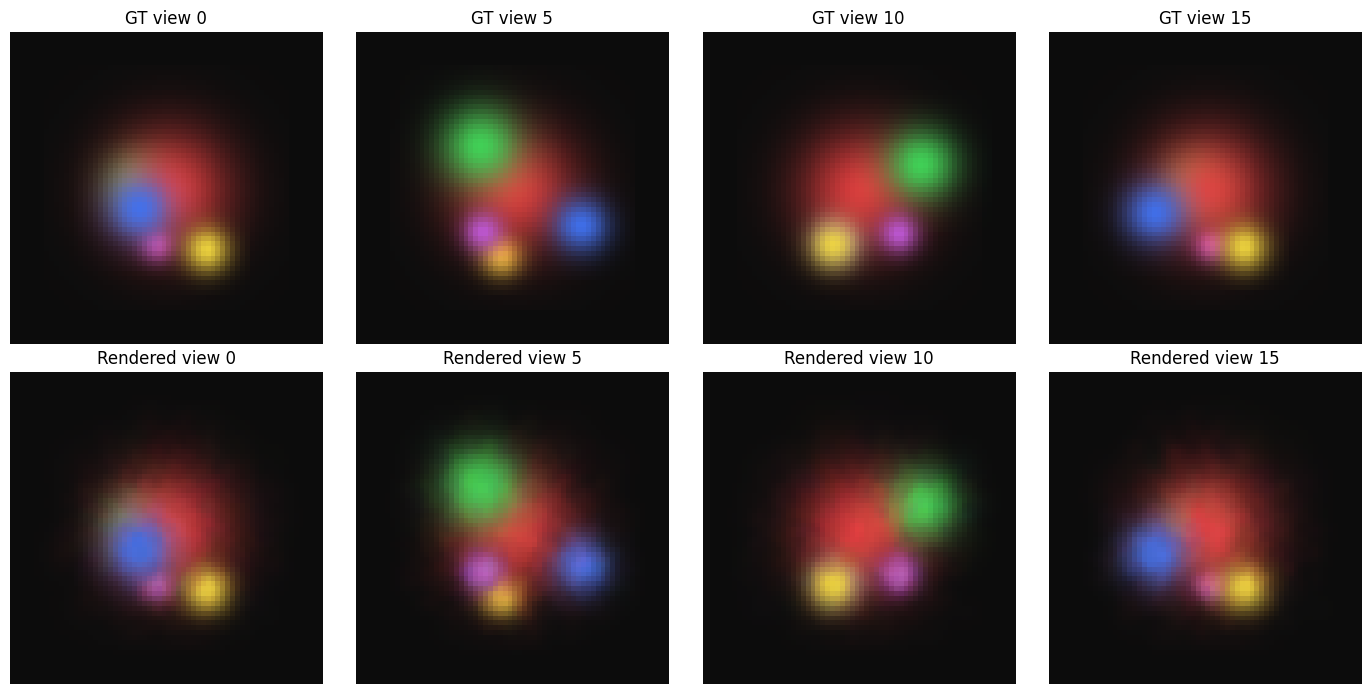

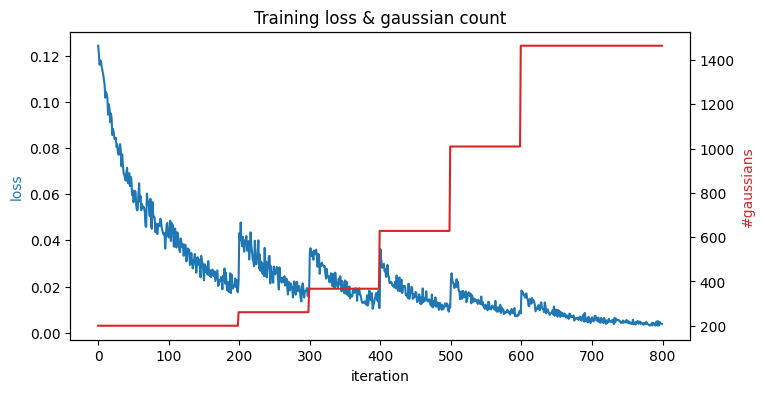

In [ ]:

IMAGE_SIZE = 64
N_VIEWS = 16

scene = SyntheticScene(device)
cameras = SyntheticScene.make_cameras(N_VIEWS, radius=3.0, height=1.0, image_size=IMAGE_SIZE, device=device)
renderer = GaussianRenderer(IMAGE_SIZE, IMAGE_SIZE, bg_color=(0.05, 0.05, 0.05))
dataset = MultiViewDataset(scene, renderer, cameras)

gaussians = GaussianModel.random_init(n_points=200, scene_extent=1.0, device=device)
trainer = Trainer(gaussians, renderer, dataset, scene_extent=1.0)
trainer.train(n_iters=800, density_start=150, density_end=600, density_every=100, log_every=50)


@torch.no_grad()
def show_results(trainer):
    idxs = np.linspace(0, len(trainer.dataset.cameras) - 1, 4).astype(int)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for col, i in enumerate(idxs):
        cam, gt = trainer.dataset.cameras[i], trainer.dataset.images[i]
        pred = trainer.renderer.render(trainer.gaussians, cam).cpu()
        axes[0, col].imshow(gt.numpy());   axes[0, col].set_title(f"GT view {i}");       axes[0, col].axis("off")
        axes[1, col].imshow(pred.numpy()); axes[1, col].set_title(f"Rendered view {i}"); axes[1, col].axis("off")
    plt.tight_layout(); plt.show()

    fig, ax1 = plt.subplots(figsize=(8, 4))
    ax1.plot(trainer.loss_history, color="tab:blue"); ax1.set_ylabel("loss", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(trainer.n_points_history, color="tab:red"); ax2.set_ylabel("#gaussians", color="tab:red")
    ax1.set_xlabel("iteration"); plt.title("Training loss & gaussian count")
    plt.show()

show_results(trainer)